In [ ]:
from google.colab import userdata
import os
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
print("Credentials loaded")

Credentials loaded


In [ ]:
import kagglehub
path = kagglehub.dataset_download("uysalserkan/fault-induction-motor-dataset")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'fault-induction-motor-dataset' dataset.
Path to dataset files: /kaggle/input/fault-induction-motor-dataset


In [ ]:
import os
for root, dirs, files in os.walk(path):
    depth = root.replace(path, '').count(os.sep)
    if depth <= 2:
        print(root, '| folders:', dirs[:10], '| files:', len(files))

/kaggle/input/fault-induction-motor-dataset | folders: ['imbalance', 'normal'] | files: 0
/kaggle/input/fault-induction-motor-dataset/imbalance | folders: ['imbalance'] | files: 0
/kaggle/input/fault-induction-motor-dataset/imbalance/imbalance | folders: ['20g', '35g', '25g', '10g', '15g', '30g', '6g'] | files: 0
/kaggle/input/fault-induction-motor-dataset/normal | folders: ['normal'] | files: 0
/kaggle/input/fault-induction-motor-dataset/normal/normal | folders: [] | files: 49


In [ ]:
import pandas as pd, glob
f = glob.glob(os.path.join(path, '**', '*.csv'), recursive=True)[0]
print(f)
df = pd.read_csv(f, header=None)
print(df.shape)
print(df.head())

/kaggle/input/fault-induction-motor-dataset/imbalance/imbalance/20g/45.4656.csv
(250000, 8)
         0        1        2        3         4         5       6         7
0 -0.70767 -0.63392 -1.72150 -0.27016  0.070163  0.005762 -1.1051  0.072821
1 -0.61342  0.24339 -1.03460 -0.26390  0.071499  0.011409 -1.0099 -0.130670
2 -0.71770 -0.62986 -1.82670 -0.35370  0.076579  0.013399 -1.1898  0.300310
3 -0.68657 -0.11612 -0.87464 -0.21653  0.077202  0.017358 -1.0530 -0.309260
4 -0.73878 -0.38263 -1.74170 -0.23501  0.077189  0.016543 -1.1172  0.389460


In [ ]:
import os
for root, dirs, files in os.walk(path):
    if files:
        print(root, '| files:', len(files))

/kaggle/input/fault-induction-motor-dataset/imbalance/imbalance/20g | files: 49
/kaggle/input/fault-induction-motor-dataset/imbalance/imbalance/35g | files: 45
/kaggle/input/fault-induction-motor-dataset/imbalance/imbalance/25g | files: 47
/kaggle/input/fault-induction-motor-dataset/imbalance/imbalance/10g | files: 48
/kaggle/input/fault-induction-motor-dataset/imbalance/imbalance/15g | files: 48
/kaggle/input/fault-induction-motor-dataset/imbalance/imbalance/30g | files: 47
/kaggle/input/fault-induction-motor-dataset/imbalance/imbalance/6g | files: 49
/kaggle/input/fault-induction-motor-dataset/normal/normal | files: 49


In [ ]:
import os
import random
import numpy as np
import tensorflow as tf

SEED = 42

os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Optional but recommended for full determinism on GPU/TPU too
tf.keras.utils.set_random_seed(SEED)

print(f"All random seeds set to {SEED}")

All random seeds set to 42


In [ ]:
import os, glob
import numpy as np
import pandas as pd
from scipy.signal import decimate

original_fs = 50000
fs = 1000
decim_factor = original_fs // fs  # 50
window_size = fs  # 1 second = 1000 points after decimation

normal_files = glob.glob(os.path.join(path, 'normal', 'normal', '*.csv'))
imbalance_files = glob.glob(os.path.join(path, 'imbalance', 'imbalance', '*', '*.csv'))

print(f"Normal files: {len(normal_files)}, Imbalance files: {len(imbalance_files)}")

# Balance classes: cap imbalance file count near normal's count
np.random.seed(42)
imbalance_files = list(np.random.choice(imbalance_files, size=min(len(imbalance_files), 60), replace=False))

# File-wise split BEFORE windowing (prevents leakage)
def split_files(files, test_frac=0.2):
    files = list(files)
    np.random.shuffle(files)
    n_test = int(len(files) * test_frac)
    return files[n_test:], files[:n_test]

normal_train_f, normal_test_f = split_files(normal_files)
imb_train_f, imb_test_f = split_files(imbalance_files)

def load_windows(files, label, col_vib=2, col_mic=7):
    X_vib, X_mic, y = [], [], []
    for f in files:
        df = pd.read_csv(f, header=None)
        vib = decimate(df.iloc[:, col_vib].values, decim_factor, ftype='iir', zero_phase=True)
        mic = decimate(df.iloc[:, col_mic].values, decim_factor, ftype='iir', zero_phase=True)
        n_windows = len(vib) // window_size
        for i in range(n_windows):
            X_vib.append(vib[i*window_size:(i+1)*window_size])
            X_mic.append(mic[i*window_size:(i+1)*window_size])
            y.append(label)
    return np.array(X_vib), np.array(X_mic), np.array(y)

Xv_train_n, Xm_train_n, y_train_n = load_windows(normal_train_f, 0)
Xv_train_i, Xm_train_i, y_train_i = load_windows(imb_train_f, 1)
Xv_test_n, Xm_test_n, y_test_n = load_windows(normal_test_f, 0)
Xv_test_i, Xm_test_i, y_test_i = load_windows(imb_test_f, 1)

Xv_train = np.concatenate([Xv_train_n, Xv_train_i])
Xm_train = np.concatenate([Xm_train_n, Xm_train_i])
y_train = np.concatenate([y_train_n, y_train_i])
Xv_test = np.concatenate([Xv_test_n, Xv_test_i])
Xm_test = np.concatenate([Xm_test_n, Xm_test_i])
y_test = np.concatenate([y_test_n, y_test_i])

print(f"Train windows: {len(y_train)}, Test windows: {len(y_test)}")
print(f"Train class balance: {np.bincount(y_train)}, Test: {np.bincount(y_test)}")

Normal files: 49, Imbalance files: 333
Train windows: 440, Test windows: 105
Train class balance: [200 240], Test: [45 60]


In [ ]:
def compute_fft_batch(X):
    fft_out = []
    for sig in X:
        mag = np.abs(np.fft.rfft(sig)) / len(sig)
        fft_out.append(mag[:250])  # keep 250 bins -> small enough for ESP32
    return np.array(fft_out)

Xv_train_fft = compute_fft_batch(Xv_train)
Xm_train_fft = compute_fft_batch(Xm_train)
Xv_test_fft = compute_fft_batch(Xv_test)
Xm_test_fft = compute_fft_batch(Xm_test)

class_names = ['Normal', 'Imbalance']

In [ ]:
from tensorflow.keras import layers, models
import tensorflow as tf

Xv_train_cnn = Xv_train_fft.reshape((-1, 250, 1))
Xv_test_cnn = Xv_test_fft.reshape((-1, 250, 1))

model_vib = models.Sequential([
    layers.Conv1D(16, 5, activation='relu', input_shape=(250, 1)),
    layers.MaxPooling1D(2),
    layers.Conv1D(32, 3, activation='relu'),
    layers.MaxPooling1D(2),
    layers.Flatten(),
    layers.Dense(32, activation='relu'),
    layers.Dense(2, activation='softmax')
])
model_vib.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_vib = model_vib.fit(Xv_train_cnn, y_train, epochs=15, batch_size=16,
                          validation_data=(Xv_test_cnn, y_test), verbose=1)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.5273 - loss: 0.6823 - val_accuracy: 0.5714 - val_loss: 0.6633
Epoch 2/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5568 - loss: 0.6013 - val_accuracy: 0.9048 - val_loss: 0.5937
Epoch 3/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8409 - loss: 0.4722 - val_accuracy: 0.9143 - val_loss: 0.4337
Epoch 4/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8500 - loss: 0.3911 - val_accuracy: 0.8571 - val_loss: 0.3579
Epoch 5/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8500 - loss: 0.3513 - val_accuracy: 0.9048 - val_loss: 0.2905
Epoch 6/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8523 - loss: 0.3312 - val_accuracy: 0.9048 - val_loss: 0.2625
Epoch 7/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8591 - loss: 0.3192 - val_accuracy: 0.9048 - val_loss: 0.2630
Epoch 8/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8750 - loss: 0.3121 - val_accuracy: 0.9048 - val_lo

In [ ]:
from tensorflow.keras import layers, models
import tensorflow as tf

Xv_train_cnn = Xv_train_fft.reshape((-1, 250, 1))
Xv_test_cnn = Xv_test_fft.reshape((-1, 250, 1))

model_vib = models.Sequential([
    layers.Conv1D(16, 5, activation='relu', input_shape=(250, 1)),
    layers.MaxPooling1D(2),
    layers.Conv1D(32, 3, activation='relu'),
    layers.MaxPooling1D(2),
    layers.Flatten(),
    layers.Dense(32, activation='relu'),
    layers.Dense(2, activation='softmax')
])
model_vib.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_vib = model_vib.fit(Xv_train_cnn, y_train, epochs=15, batch_size=16,
                          validation_data=(Xv_test_cnn, y_test), verbose=1)

Epoch 1/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.5273 - loss: 0.6706 - val_accuracy: 0.5714 - val_loss: 0.6459
Epoch 2/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5591 - loss: 0.5595 - val_accuracy: 0.8952 - val_loss: 0.5338
Epoch 3/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8341 - loss: 0.4356 - val_accuracy: 0.8571 - val_loss: 0.3949
Epoch 4/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8523 - loss: 0.3674 - val_accuracy: 0.8571 - val_loss: 0.3324
Epoch 5/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8614 - loss: 0.3436 - val_accuracy: 0.9048 - val_loss: 0.2880
Epoch 6/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8636 - loss: 0.3303 - val_accuracy: 0.9048 - val_loss: 0.2944
Epoch 7/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8591 - loss: 0.3163 - val_accuracy: 0.9048 - val_loss: 0.3032
Epoch 8/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8659 - loss: 0.2915 - val_accuracy: 0.9048 - v

In [ ]:
Xm_train_cnn = Xm_train_fft.reshape((-1, 250, 1))
Xm_test_cnn = Xm_test_fft.reshape((-1, 250, 1))

vib_input = layers.Input(shape=(250, 1), name='vibration')
mic_input = layers.Input(shape=(250, 1), name='microphone')

def branch(x):
    x = layers.Conv1D(16, 5, activation='relu')(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(32, 3, activation='relu')(x)
    x = layers.MaxPooling1D(2)(x)
    return layers.Flatten()(x)

v = branch(vib_input)
m = branch(mic_input)
merged = layers.Concatenate()([v, m])
d = layers.Dense(32, activation='relu')(merged)
out = layers.Dense(2, activation='softmax')(d)

model_fusion = models.Model(inputs=[vib_input, mic_input], outputs=out)
model_fusion.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_fusion = model_fusion.fit([Xv_train_cnn, Xm_train_cnn], y_train, epochs=15, batch_size=16,
                                validation_data=([Xv_test_cnn, Xm_test_cnn], y_test), verbose=1)

Epoch 1/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.5432 - loss: 0.6678 - val_accuracy: 0.5714 - val_loss: 0.6450
Epoch 2/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6477 - loss: 0.5526 - val_accuracy: 0.9048 - val_loss: 0.5319
Epoch 3/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8455 - loss: 0.4232 - val_accuracy: 0.9048 - val_loss: 0.3781
Epoch 4/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8500 - loss: 0.3687 - val_accuracy: 0.9048 - val_loss: 0.3068
Epoch 5/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8636 - loss: 0.3275 - val_accuracy: 0.9048 - val_loss: 0.2784
Epoch 6/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8636 - loss: 0.3103 - val_accuracy: 0.9048 - val_loss: 0.2571
Epoch 7/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8636 - loss: 0.3002 - val_accuracy: 0.9048 - val_loss: 0.2820
Epoch 8/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8705 - loss: 0.2845 - val_accuracy: 0.9048 - v

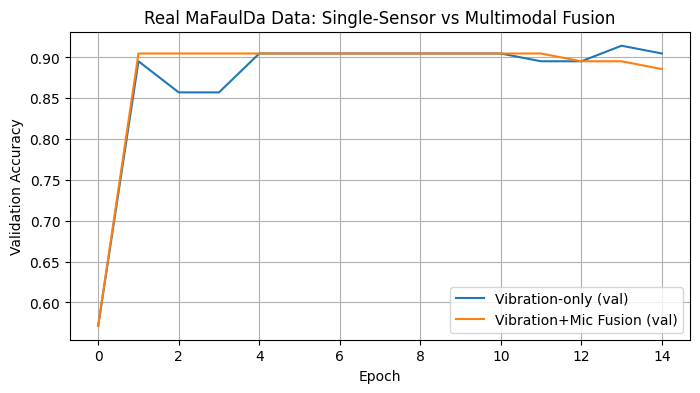

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


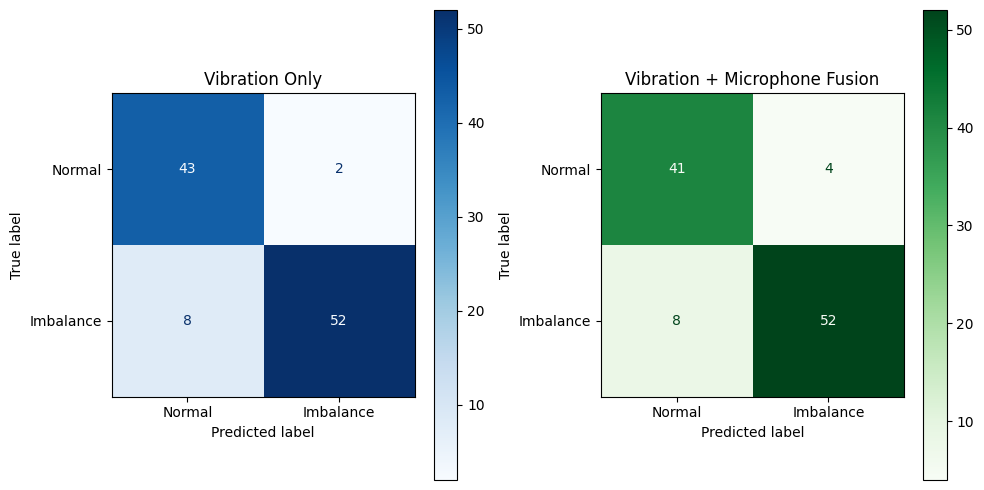

Vibration-only test accuracy: 0.905
Fusion test accuracy: 0.886


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Accuracy comparison
plt.figure(figsize=(8,4))
plt.plot(hist_vib.history['val_accuracy'], label='Vibration-only (val)')
plt.plot(hist_fusion.history['val_accuracy'], label='Vibration+Mic Fusion (val)')
plt.xlabel('Epoch'); plt.ylabel('Validation Accuracy'); plt.legend(); plt.grid(True)
plt.title('Real MaFaulDa Data: Single-Sensor vs Multimodal Fusion')
plt.savefig('accuracy_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# Confusion matrices
y_pred_vib = np.argmax(model_vib.predict(Xv_test_cnn), axis=1)
y_pred_fusion = np.argmax(model_fusion.predict([Xv_test_cnn, Xm_test_cnn]), axis=1)

fig, axes = plt.subplots(1, 2, figsize=(10,5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_vib), display_labels=class_names).plot(ax=axes[0], cmap='Blues')
axes[0].set_title('Vibration Only')
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_fusion), display_labels=class_names).plot(ax=axes[1], cmap='Greens')
axes[1].set_title('Vibration + Microphone Fusion')
plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Vibration-only test accuracy: {model_vib.evaluate(Xv_test_cnn, y_test, verbose=0)[1]:.3f}")
print(f"Fusion test accuracy: {model_fusion.evaluate([Xv_test_cnn, Xm_test_cnn], y_test, verbose=0)[1]:.3f}")

In [ ]:
# find which test windows were misclassified
wrong_idx = np.where(y_pred_vib != y_test)[0]
print("Misclassified count:", len(wrong_idx))
print("True labels of errors:", y_test[wrong_idx])


Misclassified count: 10
True labels of errors: [0 0 1 1 1 1 1 1 1 1]


In [ ]:
test_files_ordered = imb_test_f  # order used in load_windows for label 1
# find how many windows came from each file, so we can map global index -> file
window_counts = []
for f in test_files_ordered:
    df = pd.read_csv(f, header=None)
    vib = decimate(df.iloc[:, 2].values, decim_factor, ftype='iir', zero_phase=True)
    window_counts.append(len(vib) // window_size)

# global index of imbalance windows starts after all normal test windows
offset = len(y_test_n)
imb_wrong_local = wrong_idx - offset  # index within imbalance test windows only

cum = 0
for f, n in zip(test_files_ordered, window_counts):
    if any(cum <= w < cum+n for w in imb_wrong_local):
        print(f)
    cum += n

/kaggle/input/fault-induction-motor-dataset/imbalance/imbalance/20g/14.336.csv
/kaggle/input/fault-induction-motor-dataset/imbalance/imbalance/6g/59.392.csv


In [ ]:
# Convert vibration-only model to TFLite int8
def representative_dataset():
    for i in range(min(100, len(Xv_train_cnn))):
        yield [Xv_train_cnn[i:i+1].astype(np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(model_vib)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_model = converter.convert()
print(f"Quantized model size: {len(tflite_model)/1024:.2f} KB")

with open('model_int8.tflite', 'wb') as f:
    f.write(tflite_model)

# Check accuracy after quantization
interpreter = tf.lite.Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

in_scale, in_zero = input_details[0]['quantization']
correct = 0
for i in range(len(Xv_test_cnn)):
    x = Xv_test_cnn[i:i+1]
    x_q = (x / in_scale + in_zero).astype(np.int8)
    interpreter.set_tensor(input_details[0]['index'], x_q)
    interpreter.invoke()
    pred = np.argmax(interpreter.get_tensor(output_details[0]['index']))
    if pred == y_test[i]:
        correct += 1
print(f"Post-quantization accuracy: {correct/len(y_test):.3f}")

Saved artifact at '/tmp/tmpb23o4rw6'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 250, 1), dtype=tf.float32, name='keras_tensor_8')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  134804670100688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804670102992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804670098768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804670102608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804670102800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804670102416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804670101072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804670102224: TensorSpec(shape=(), dtype=tf.resource, name=None)
Quantized model size: 70.70 KB
Post-quantization accuracy: 0.829


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:
def representative_dataset():
    for i in range(min(200, len(Xv_train_cnn))):
        sample = Xv_train_cnn[i:i+1].astype(np.float32)
        yield [sample]

converter = tf.lite.TFLiteConverter.from_keras_model(model_vib)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8
converter._experimental_disable_per_channel = False  # ensure per-channel calibration runs

tflite_model = converter.convert()
print(f"Quantized size: {len(tflite_model)/1024:.2f} KB")

Saved artifact at '/tmp/tmpijdv85_8'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 250, 1), dtype=tf.float32, name='keras_tensor_8')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  134804670100688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804670102992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804670098768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804670102608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804670102800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804670102416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804670101072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804670102224: TensorSpec(shape=(), dtype=tf.resource, name=None)
Quantized size: 70.70 KB


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


In [ ]:
interpreter = tf.lite.Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

in_scale, in_zero = input_details[0]['quantization']
correct = 0
for i in range(len(Xv_test_cnn)):
    x = Xv_test_cnn[i:i+1]
    x_q = (x / in_scale + in_zero).astype(np.int8)
    interpreter.set_tensor(input_details[0]['index'], x_q)
    interpreter.invoke()
    pred = np.argmax(interpreter.get_tensor(output_details[0]['index']))
    if pred == y_test[i]:
        correct += 1
print(f"Post-quantization accuracy: {correct/len(y_test):.3f}")

Post-quantization accuracy: 0.838


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:
# Reduce FFT bins from 250 -> 128, and shrink the CNN
def compute_fft_batch_small(X, n_bins=128):
    fft_out = []
    for sig in X:
        mag = np.abs(np.fft.rfft(sig)) / len(sig)
        fft_out.append(mag[:n_bins])
    return np.array(fft_out)

Xv_train_fft_s = compute_fft_batch_small(Xv_train)
Xv_test_fft_s = compute_fft_batch_small(Xv_test)

Xv_train_cnn_s = Xv_train_fft_s.reshape((-1, 128, 1))
Xv_test_cnn_s = Xv_test_fft_s.reshape((-1, 128, 1))

model_small = models.Sequential([
    layers.Conv1D(8, 5, activation='relu', input_shape=(128, 1)),
    layers.MaxPooling1D(2),
    layers.Conv1D(16, 3, activation='relu'),
    layers.MaxPooling1D(2),
    layers.Flatten(),
    layers.Dense(16, activation='relu'),
    layers.Dense(2, activation='softmax')
])
model_small.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_small = model_small.fit(Xv_train_cnn_s, y_train, epochs=15, batch_size=16,
                              validation_data=(Xv_test_cnn_s, y_test), verbose=1)
print(f"Float32 test accuracy: {model_small.evaluate(Xv_test_cnn_s, y_test, verbose=0)[1]:.3f}")

Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.5386 - loss: 0.6737 - val_accuracy: 0.5714 - val_loss: 0.6676
Epoch 2/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5455 - loss: 0.6307 - val_accuracy: 0.5714 - val_loss: 0.6368
Epoch 3/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5636 - loss: 0.5667 - val_accuracy: 0.8571 - val_loss: 0.5786
Epoch 4/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8318 - loss: 0.4940 - val_accuracy: 0.9048 - val_loss: 0.5030
Epoch 5/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8455 - loss: 0.4342 - val_accuracy: 0.8667 - val_loss: 0.4328
Epoch 6/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8432 - loss: 0.3952 - val_accuracy: 0.8571 - val_loss: 0.3855
Epoch 7/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8477 - loss: 0.3710 - val_accuracy: 0.8571 - val_loss: 0.3405
Epoch 8/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8523 - loss: 0.3554 - val_accuracy: 0.9048 - val_loss: 0.3146
Ep

In [ ]:
def representative_dataset_small():
    for i in range(min(200, len(Xv_train_cnn_s))):
        yield [Xv_train_cnn_s[i:i+1].astype(np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(model_small)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset_small
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_small = converter.convert()
print(f"Small quantized model size: {len(tflite_small)/1024:.2f} KB")

with open('model_small_int8.tflite', 'wb') as f:
    f.write(tflite_small)

Saved artifact at '/tmp/tmp2nqqyqw6'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 1), dtype=tf.float32, name='keras_tensor_29')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  134804039218576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804039213008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804039213776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804039218192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804039218384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804039217616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804039217808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804039217424: TensorSpec(shape=(), dtype=tf.resource, name=None)
Small quantized model size: 15.91 KB


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


In [ ]:
interpreter = tf.lite.Interpreter(model_content=tflite_small)
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

in_scale, in_zero = input_details[0]['quantization']
correct = 0
for i in range(len(Xv_test_cnn_s)):
    x = Xv_test_cnn_s[i:i+1]
    x_q = (x / in_scale + in_zero).astype(np.int8)
    interpreter.set_tensor(input_details[0]['index'], x_q)
    interpreter.invoke()
    pred = np.argmax(interpreter.get_tensor(output_details[0]['index']))
    if pred == y_test[i]:
        correct += 1
print(f"Small model post-quantization accuracy: {correct/len(y_test):.3f}")

Small model post-quantization accuracy: 0.819


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:
def representative_dataset_small():
    idx = np.random.permutation(len(Xv_train_cnn_s))[:200]
    for i in idx:
        yield [Xv_train_cnn_s[i:i+1].astype(np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(model_small)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset_small
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_small = converter.convert()
print(f"Small quantized model size: {len(tflite_small)/1024:.2f} KB")

Saved artifact at '/tmp/tmpm71ssf5b'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 1), dtype=tf.float32, name='keras_tensor_29')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  134804039218576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804039213008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804039213776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804039218192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804039218384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804039217616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804039217808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804039217424: TensorSpec(shape=(), dtype=tf.resource, name=None)
Small quantized model size: 15.91 KB


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


In [ ]:
interpreter = tf.lite.Interpreter(model_content=tflite_small)
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

in_scale, in_zero = input_details[0]['quantization']
correct = 0
for i in range(len(Xv_test_cnn_s)):
    x = Xv_test_cnn_s[i:i+1]
    x_q = (x / in_scale + in_zero).astype(np.int8)
    interpreter.set_tensor(input_details[0]['index'], x_q)
    interpreter.invoke()
    pred = np.argmax(interpreter.get_tensor(output_details[0]['index']))
    if pred == y_test[i]:
        correct += 1

print(f"Small model post-quantization accuracy: {correct/len(y_test):.3f}")

Small model post-quantization accuracy: 0.905


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


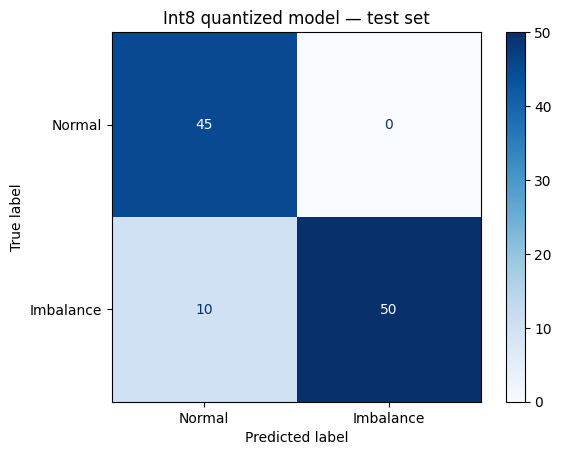

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

preds = []
interpreter2 = tf.lite.Interpreter(model_content=tflite_small)
interpreter2.allocate_tensors()
in_d = interpreter2.get_input_details()
out_d = interpreter2.get_output_details()
sc, zp = in_d[0]['quantization']

for i in range(len(Xv_test_cnn_s)):
    x_q = (Xv_test_cnn_s[i:i+1] / sc + zp).astype(np.int8)
    interpreter2.set_tensor(in_d[0]['index'], x_q)
    interpreter2.invoke()
    preds.append(np.argmax(interpreter2.get_tensor(out_d[0]['index'])))

cm = confusion_matrix(y_test, preds)
disp = ConfusionMatrixDisplay(cm, display_labels=["Normal", "Imbalance"])
disp.plot(cmap="Blues")
plt.title("Int8 quantized model — test set")
plt.savefig("confusion_matrix_int8.png", dpi=150, bbox_inches="tight")
plt.show()

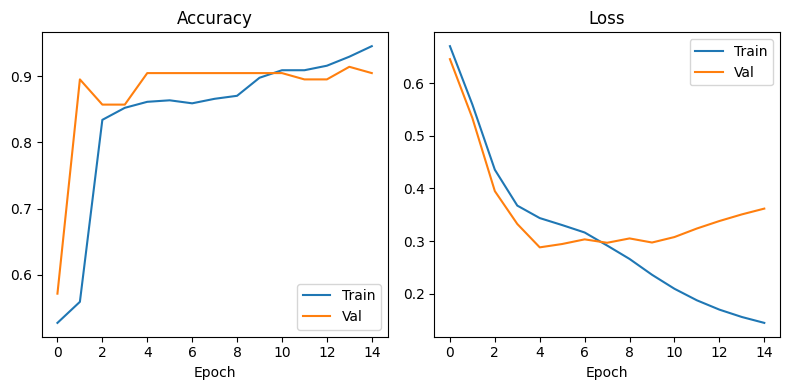

In [ ]:
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.plot(hist_vib.history['accuracy'], label='Train')
plt.plot(hist_vib.history['val_accuracy'], label='Val')
plt.title('Accuracy'); plt.legend(); plt.xlabel('Epoch')

plt.subplot(1, 2, 2)
plt.plot(hist_vib.history['loss'], label='Train')
plt.plot(hist_vib.history['val_loss'], label='Val')
plt.title('Loss'); plt.legend(); plt.xlabel('Epoch')

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
def generate_signal(fault_type, n_samples=1000, fs=1000):
    t = np.linspace(0, 1, fs)
    if fault_type == 'normal':
        return np.sin(2*np.pi*50*t) + 0.1*np.random.randn(fs)
    elif fault_type == 'imbalance':
        return np.sin(2*np.pi*50*t) + 0.4*np.sin(2*np.pi*25*t) + 0.1*np.random.randn(fs)
    elif fault_type == 'misalignment':
        return np.sin(2*np.pi*50*t) + 0.3*np.sin(2*np.pi*100*t) + 0.1*np.random.randn(fs)
    elif fault_type == 'bearing':
        # Bearing fault: random impulses at ~150 Hz
        sig = np.sin(2*np.pi*50*t)
        impulses = np.zeros(fs)
        for idx in range(0, fs, int(fs/150)):
            impulses[idx] = 0.8
        return sig + impulses + 0.1*np.random.randn(fs)

In [ ]:
import os
os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)

# Paste your own username and key here
kaggle_config = {
    "username": "https://www.kaggle.com/divakarrv",
    "key": "KGAT_ee2a81469cd20756180e04dca674d91d"
}

import json
with open(os.path.expanduser("~/.kaggle/kaggle.json"), "w") as f:
    json.dump(kaggle_config, f)

os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
print("Done")

Done


In [ ]:
!kaggle datasets download -d uciml/mafaulda -p ./mafaulda --unzip
!ls ./mafaulda

403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDatasetMetadata
ls: cannot access './mafaulda': No such file or directory


In [ ]:
def generate_signal(fault_type, n_samples=1000, fs=1000):
    t = np.linspace(0, 1, fs)
    if fault_type == 'normal':
        return np.sin(2*np.pi*50*t) + 0.1*np.random.randn(fs)
    elif fault_type == 'imbalance':
        return np.sin(2*np.pi*50*t) + 0.4*np.sin(2*np.pi*25*t) + 0.1*np.random.randn(fs)
    elif fault_type == 'misalignment':
        return np.sin(2*np.pi*50*t) + 0.3*np.sin(2*np.pi*100*t) + 0.1*np.random.randn(fs)
    elif fault_type == 'bearing':
        sig = np.sin(2*np.pi*50*t)
        impulses = np.zeros(fs)
        for idx in range(0, fs, int(fs/150)):
            impulses[idx] = 0.8
        return sig + impulses + 0.1*np.random.randn(fs)

In [ ]:
!kaggle datasets download -d shreyas189/mafaulda -p ./mafaulda --unzip
!ls ./mafaulda


403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDatasetMetadata
ls: cannot access './mafaulda': No such file or directory


In [ ]:
!kaggle datasets download -d pythonafroz/mafaulda-readings-for-machine-learning -p ./mafaulda --unzip
!ls ./mafaulda

403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDatasetMetadata
ls: cannot access './mafaulda': No such file or directory


In [ ]:
!kaggle datasets download -d shreyas189/mafaulda -p ./mafaulda --unzip
!ls ./mafaulda


403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDatasetMetadata
ls: cannot access './mafaulda': No such file or directory


In [ ]:
!kaggle datasets download -d uciml/mafaulda -p ./mafaulda --unzip
!ls ./mafaulda

403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDatasetMetadata
ls: cannot access './mafaulda': No such file or directory


In [ ]:
!kaggle datasets download -d pythonafroz/mafaulda-readings-for-machine-learning -p ./mafaulda --unzip
!ls ./mafaulda

403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDatasetMetadata
ls: cannot access './mafaulda': No such file or directory


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_10 (Conv1D)              │ (None, 126, 16)        │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_10 (MaxPooling1D) │ (None, 63, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_11 (Conv1D)              │ (None, 61, 32)         │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_11 (MaxPooling1D) │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │        30,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,516 (127.02 KB)

 Trainable params: 32,516 (127.02 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.6562 - loss: 1.3567 - val_accuracy: 1.0000 - val_loss: 1.3209
Epoch 2/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9688 - loss: 1.2429 - val_accuracy: 0.7188 - val_loss: 1.1418
Epoch 3/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8958 - loss: 0.9539 - val_accuracy: 0.7188 - val_loss: 0.7628
Epoch 4/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8906 - loss: 0.5554 - val_accuracy: 0.8542 - val_loss: 0.4300
Epoch 5/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9648 - loss: 0.3304 - val_accuracy: 1.0000 - val_loss: 0.2951
Epoch 6/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 1.0000 - loss: 0.2388 - val_accuracy: 1.0000 - val_loss: 0.2202
Epoch 7/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 1.0000 - loss: 0.1735 - val_accuracy: 1.0000 - val_loss: 0.1521
Epoch 8/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 1.0000 - loss: 0.1124 - val_accuracy: 1.0000 - val

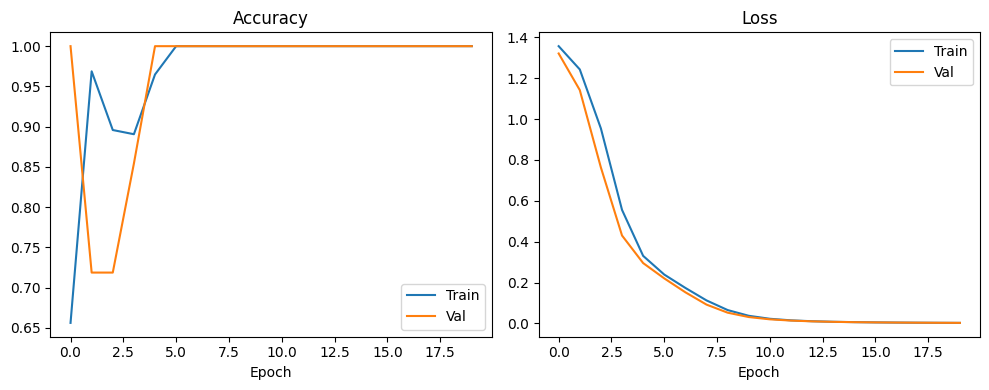

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


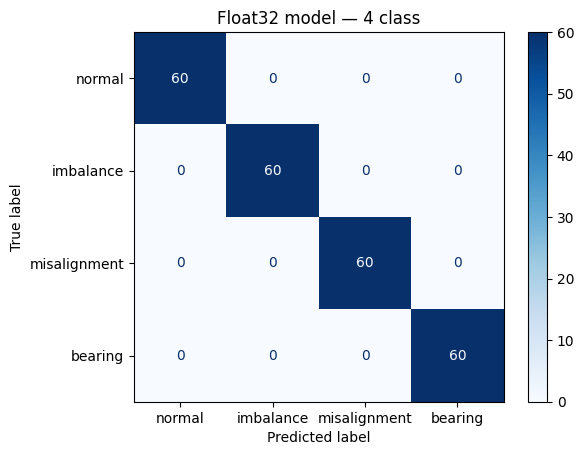

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Generate 4-class synthetic data
def generate_signal(fault_type, fs=1000):
    t = np.linspace(0, 1, fs)
    if fault_type == 'normal':
        return np.sin(2*np.pi*50*t) + 0.1*np.random.randn(fs)
    elif fault_type == 'imbalance':
        return np.sin(2*np.pi*50*t) + 0.4*np.sin(2*np.pi*25*t) + 0.1*np.random.randn(fs)
    elif fault_type == 'misalignment':
        return np.sin(2*np.pi*50*t) + 0.3*np.sin(2*np.pi*100*t) + 0.1*np.random.randn(fs)
    elif fault_type == 'bearing':
        sig = np.sin(2*np.pi*50*t)
        impulses = np.zeros(fs)
        for idx in range(0, fs, int(fs/150)):
            impulses[idx] = 0.8
        return sig + impulses + 0.1*np.random.randn(fs)

# 2. Build dataset
classes = ['normal', 'imbalance', 'misalignment', 'bearing']
X, y = [], []
for label, cls in enumerate(classes):
    for _ in range(300):
        sig = generate_signal(cls)
        fft = np.abs(np.fft.rfft(sig))[:128]
        X.append(fft)
        y.append(label)

X = np.array(X, dtype=np.float32)
y = np.array(y)
X = X / (X.max(axis=1, keepdims=True) + 1e-8)
X = X[..., np.newaxis]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Build model
model = models.Sequential([
    layers.Conv1D(16, 3, activation='relu', input_shape=(128, 1)),
    layers.MaxPooling1D(2),
    layers.Conv1D(32, 3, activation='relu'),
    layers.MaxPooling1D(2),
    layers.Flatten(),
    layers.Dense(32, activation='relu'),
    layers.Dense(4, activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

# 4. Train
history = model.fit(X_train, y_train, epochs=20, batch_size=32,
                    validation_split=0.2, verbose=1)

# 5. Evaluate
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nFloat32 test accuracy: {acc:.3f}")

# 6. Plot training curves
plt.figure(figsize=(10, 4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title('Accuracy'); plt.legend(); plt.xlabel('Epoch')
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title('Loss'); plt.legend(); plt.xlabel('Epoch')
plt.tight_layout()
plt.savefig('training_curves_4class.png', dpi=150, bbox_inches='tight')
plt.show()

# 7. Confusion matrix
y_pred = np.argmax(model.predict(X_test), axis=1)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=classes)
disp.plot(cmap='Blues')
plt.title('Float32 model — 4 class')
plt.savefig('confusion_matrix_4class.png', dpi=150, bbox_inches='tight')
plt.show()

Saved artifact at '/tmp/tmpdvvwri2d'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 1), dtype=tf.float32, name='keras_tensor_37')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  134804040372240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134807351493072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804039210896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806649710992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806649710800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806649711376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806649711184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806649715216: TensorSpec(shape=(), dtype=tf.resource, name=None)


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


4-class quantized model size: 40.80 KB
4-class int8 accuracy: 1.000


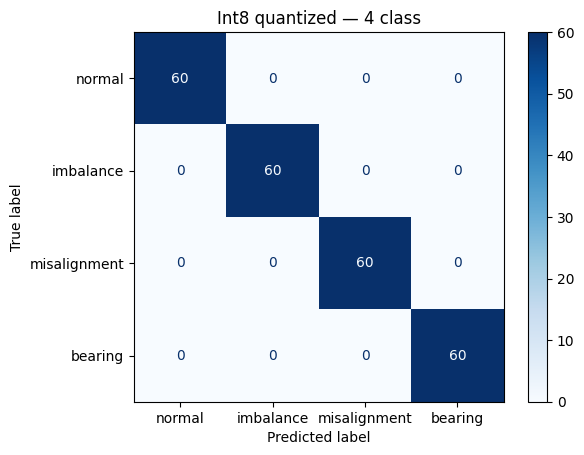

In [ ]:
# Quantize the 4-class model
def representative_dataset():
    idx = np.random.permutation(len(X_train))[:200]
    for i in idx:
        yield [X_train[i:i+1].astype(np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_model = converter.convert()
print(f"4-class quantized model size: {len(tflite_model)/1024:.2f} KB")

# Accuracy check
interpreter = tf.lite.Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()
in_d = interpreter.get_input_details()
out_d = interpreter.get_output_details()
sc, zp = in_d[0]['quantization']

preds = []
for i in range(len(X_test)):
    x_q = (X_test[i:i+1] / sc + zp).astype(np.int8)
    interpreter.set_tensor(in_d[0]['index'], x_q)
    interpreter.invoke()
    preds.append(np.argmax(interpreter.get_tensor(out_d[0]['index'])))

preds = np.array(preds)
int8_acc = np.mean(preds == y_test)
print(f"4-class int8 accuracy: {int8_acc:.3f}")

# Confusion matrix
cm = confusion_matrix(y_test, preds)
disp = ConfusionMatrixDisplay(cm, display_labels=classes)
disp.plot(cmap='Blues')
plt.title('Int8 quantized — 4 class')
plt.savefig('confusion_matrix_4class_int8.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
def generate_signal(fault_type, fs=1000):
    t = np.linspace(0, 1, fs)
    # Base motor signal same for all classes
    base = np.sin(2*np.pi*50*t) + 0.3*np.sin(2*np.pi*150*t)
    noise = 0.3*np.random.randn(fs)  # increased noise

    if fault_type == 'normal':
        return base + noise
    elif fault_type == 'imbalance':
        # 1x RPM harmonic — partially overlaps with base
        return base + 0.35*np.sin(2*np.pi*25*t + np.random.uniform(0, np.pi)) + noise
    elif fault_type == 'misalignment':
        # 2x RPM harmonic
        return base + 0.3*np.sin(2*np.pi*100*t + np.random.uniform(0, np.pi)) + noise
    elif fault_type == 'bearing':
        sig = base.copy()
        # Random impulse spacing ±10% to simulate real bearing variation
        spacing = int(fs/150 * np.random.uniform(0.9, 1.1))
        for idx in range(0, fs, spacing):
            sig[idx] += np.random.uniform(0.5, 1.0)
        return sig + noise

Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.5286 - loss: 1.3737 - val_accuracy: 0.7188 - val_loss: 1.3624
Epoch 2/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7565 - loss: 1.3419 - val_accuracy: 0.7188 - val_loss: 1.3222
Epoch 3/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7578 - loss: 1.2752 - val_accuracy: 0.7188 - val_loss: 1.2235
Epoch 4/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7578 - loss: 1.1269 - val_accuracy: 0.7188 - val_loss: 1.0311
Epoch 5/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7982 - loss: 0.8809 - val_accuracy: 0.7188 - val_loss: 0.7558
Epoch 6/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8320 - loss: 0.6076 - val_accuracy: 0.7240 - val_loss: 0.5238
Epoch 7/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8529 - loss: 0.4296 - val_accuracy: 0.7188 - val_loss: 0.4101
Epoch 8/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8555 - loss: 0.3506 - val_accuracy: 0.7760 - val_loss: 0.3573
E

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Quantized model size: 16.00 KB
Int8 accuracy: 1.000


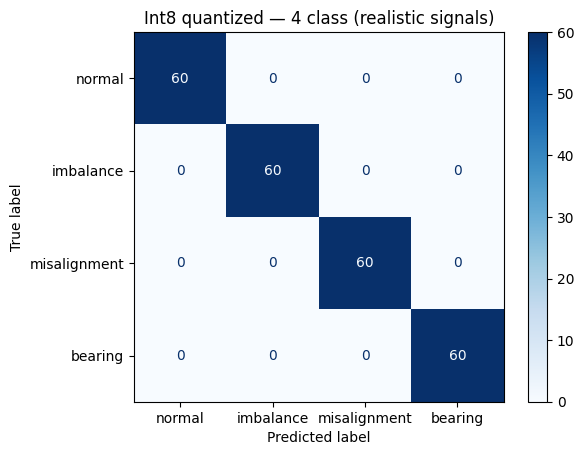

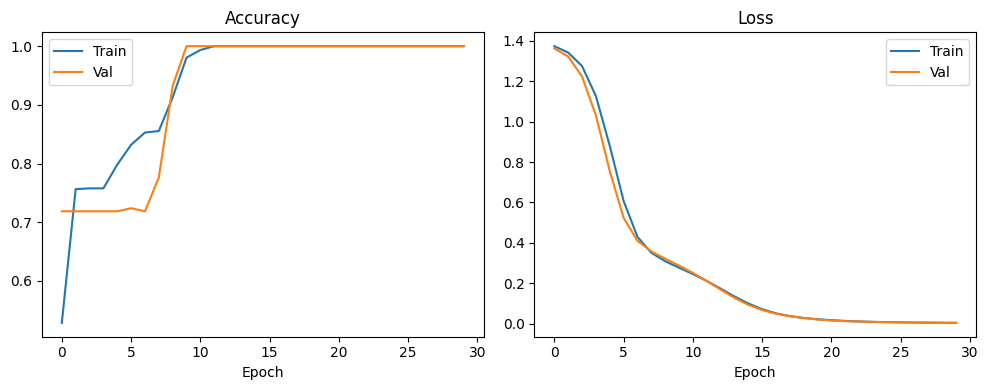

In [ ]:
# Step 1: Realistic signal generator
def generate_signal(fault_type, fs=1000):
    t = np.linspace(0, 1, fs)
    base = np.sin(2*np.pi*50*t) + 0.3*np.sin(2*np.pi*150*t)
    noise = 0.3*np.random.randn(fs)
    if fault_type == 'normal':
        return base + noise
    elif fault_type == 'imbalance':
        return base + 0.35*np.sin(2*np.pi*25*t + np.random.uniform(0, np.pi)) + noise
    elif fault_type == 'misalignment':
        return base + 0.3*np.sin(2*np.pi*100*t + np.random.uniform(0, np.pi)) + noise
    elif fault_type == 'bearing':
        sig = base.copy()
        spacing = int(fs/150 * np.random.uniform(0.9, 1.1))
        for idx in range(0, fs, spacing):
            sig[idx] += np.random.uniform(0.5, 1.0)
        return sig + noise

# Step 2: Rebuild dataset
classes = ['normal', 'imbalance', 'misalignment', 'bearing']
X, y = [], []
for label, cls in enumerate(classes):
    for _ in range(300):
        sig = generate_signal(cls)
        fft = np.abs(np.fft.rfft(sig))[:128]
        X.append(fft)
        y.append(label)

X = np.array(X, dtype=np.float32)
y = np.array(y)
X = X / (X.max(axis=1, keepdims=True) + 1e-8)
X = X[..., np.newaxis]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Step 3: Smaller model (targets <30 KB)
model = models.Sequential([
    layers.Conv1D(8, 3, activation='relu', input_shape=(128, 1)),
    layers.MaxPooling1D(2),
    layers.Conv1D(16, 3, activation='relu'),
    layers.MaxPooling1D(2),
    layers.Flatten(),
    layers.Dense(16, activation='relu'),
    layers.Dense(4, activation='softmax')
])
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=30, batch_size=32,
                    validation_split=0.2, verbose=1)

loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nFloat32 accuracy: {acc:.3f}")

# Step 4: Quantize
def representative_dataset():
    idx = np.random.permutation(len(X_train))[:200]
    for i in idx:
        yield [X_train[i:i+1].astype(np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8
tflite_model = converter.convert()
print(f"Quantized model size: {len(tflite_model)/1024:.2f} KB")

# Step 5: Int8 accuracy
interpreter = tf.lite.Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()
in_d = interpreter.get_input_details()
out_d = interpreter.get_output_details()
sc, zp = in_d[0]['quantization']

preds = []
for i in range(len(X_test)):
    x_q = (X_test[i:i+1] / sc + zp).astype(np.int8)
    interpreter.set_tensor(in_d[0]['index'], x_q)
    interpreter.invoke()
    preds.append(np.argmax(interpreter.get_tensor(out_d[0]['index'])))

preds = np.array(preds)
print(f"Int8 accuracy: {np.mean(preds == y_test):.3f}")

# Step 6: Confusion matrix
cm = confusion_matrix(y_test, preds)
disp = ConfusionMatrixDisplay(cm, display_labels=classes)
disp.plot(cmap='Blues')
plt.title('Int8 quantized — 4 class (realistic signals)')
plt.savefig('confusion_matrix_final.png', dpi=150, bbox_inches='tight')
plt.show()

# Step 7: Training curves
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title('Accuracy'); plt.legend(); plt.xlabel('Epoch')
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title('Loss'); plt.legend(); plt.xlabel('Epoch')
plt.tight_layout()
plt.savefig('training_curves_final.png', dpi=150, bbox_inches='tight')
plt.show()

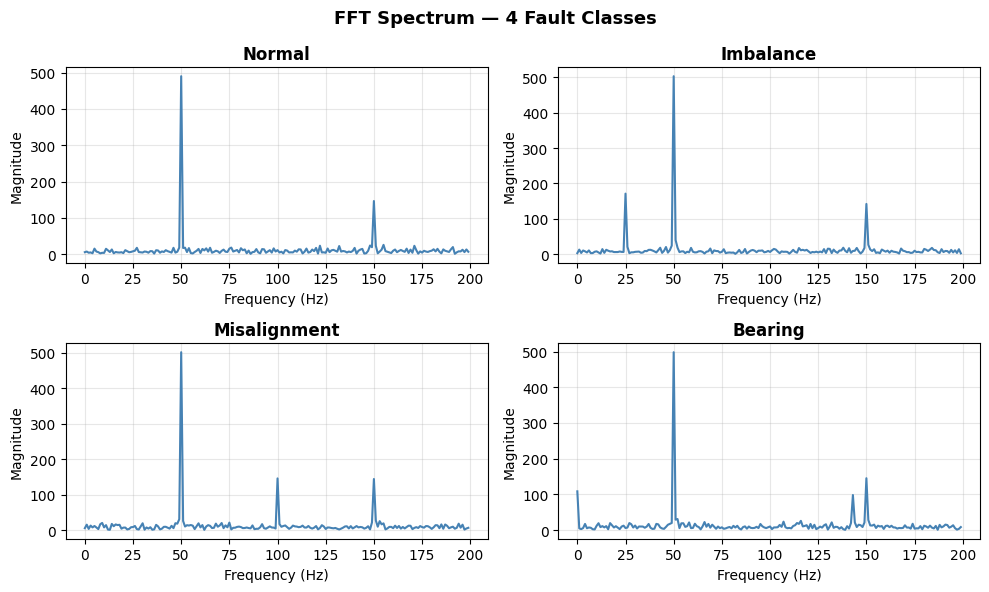

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, cls in zip(axes.flat, classes):
    sig = generate_signal(cls)
    fft = np.abs(np.fft.rfft(sig))
    freqs = np.fft.rfftfreq(len(sig), 1/1000)
    ax.plot(freqs[:200], fft[:200], color='steelblue')
    ax.set_title(cls.capitalize(), fontweight='bold')
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Magnitude')
    ax.grid(True, alpha=0.3)
plt.suptitle('FFT Spectrum — 4 Fault Classes', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fft_spectrum.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Save tflite file
with open("model.tflite", "wb") as f:
    f.write(tflite_model)

# Convert to C header using Python (no xxd needed)
with open("model.tflite", "rb") as f:
    data = f.read()

c_array = ", ".join(f"0x{b:02x}" for b in data)
c_header = f"""// Auto-generated TFLite model header
// Model size: {len(data)} bytes ({len(data)/1024:.2f} KB)
// 4-class fault classifier: Normal, Imbalance, Misalignment, Bearing

#ifndef MODEL_DATA_H
#define MODEL_DATA_H

const unsigned char model_data[] = {{
  {c_array}
}};

const int model_data_len = {len(data)};

#endif // MODEL_DATA_H
"""

with open("model_data.h", "w") as f:
    f.write(c_header)

print("C header generated successfully")
print(f"Model size: {len(data)} bytes ({len(data)/1024:.2f} KB)")
print("\nFirst 3 lines of model_data.h:")
print("\n".join(c_header.split("\n")[:5]))

C header generated successfully
Model size: 16384 bytes (16.00 KB)

First 3 lines of model_data.h:
// Auto-generated TFLite model header
// Model size: 16384 bytes (16.00 KB)
// 4-class fault classifier: Normal, Imbalance, Misalignment, Bearing

#ifndef MODEL_DATA_H


In [ ]:
# ESP32 power estimates (from datasheet)
active_current_mA = 240      # during inference
deep_sleep_current_uA = 10   # during sleep
inference_time_s = 0.03      # 30ms per inference
wake_interval_s = 60         # wake every 60 seconds

active_time_fraction = inference_time_s / wake_interval_s
sleep_time_fraction = 1 - active_time_fraction

avg_current_mA = (active_current_mA * active_time_fraction) + \
                 (deep_sleep_current_uA/1000 * sleep_time_fraction)

battery_mAh = 2000  # standard 18650 cell
battery_life_hours = battery_mAh / avg_current_mA
battery_life_days = battery_life_hours / 24

print(f"Active fraction: {active_time_fraction*100:.2f}%")
print(f"Average current: {avg_current_mA:.2f} mA")
print(f"Estimated battery life: {battery_life_days:.0f} days")

Active fraction: 0.05%
Average current: 0.13 mA
Estimated battery life: 641 days


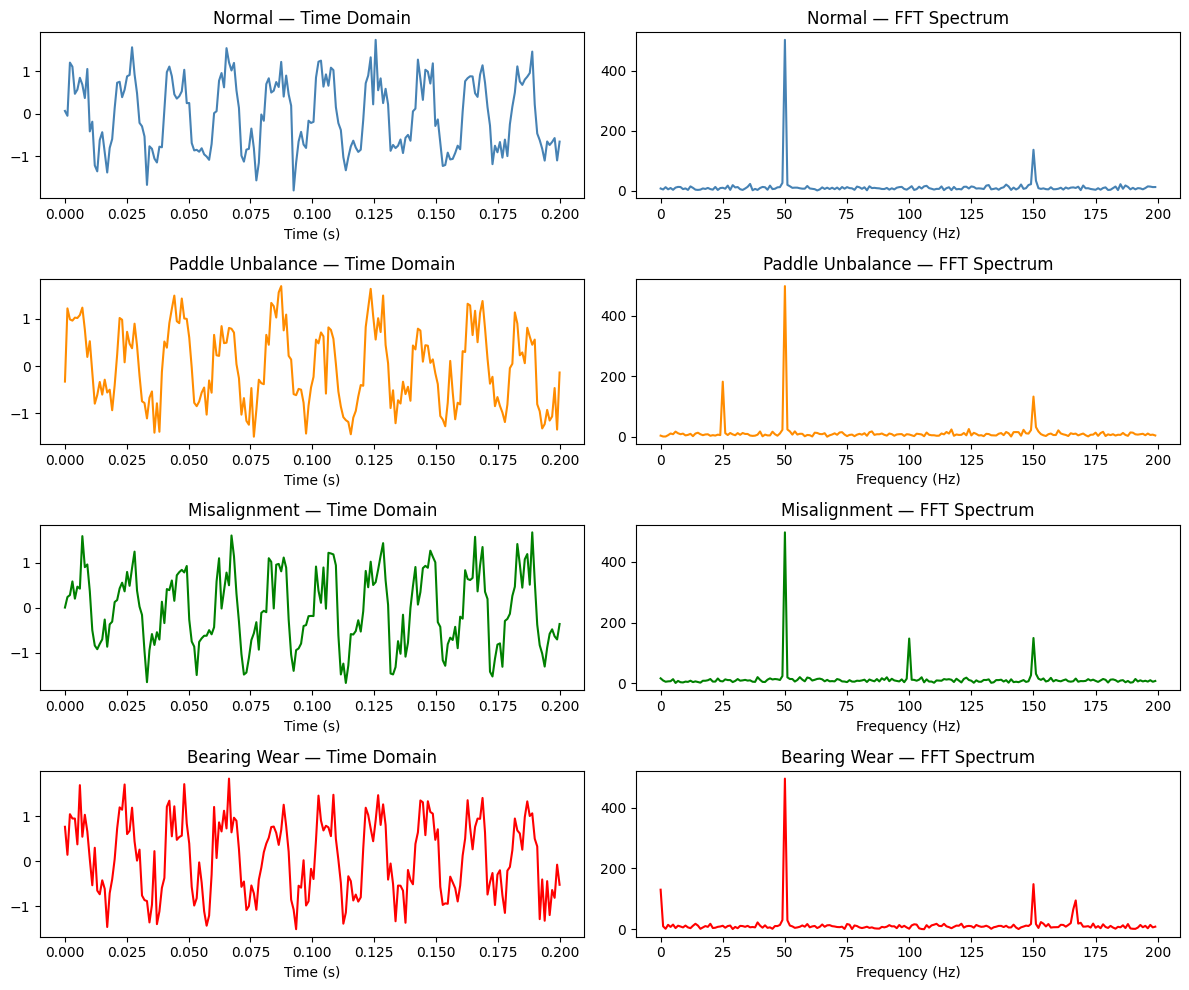

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(12, 10))
labels = ['Normal', 'Paddle Unbalance', 'Misalignment', 'Bearing Wear']
colors = ['steelblue', 'darkorange', 'green', 'red']

for i, (cls, label, color) in enumerate(zip(
        ['normal','imbalance','misalignment','bearing'], labels, colors)):
    sig = generate_signal(cls)
    t = np.linspace(0, 0.2, 200)
    fft = np.abs(np.fft.rfft(sig))
    freqs = np.fft.rfftfreq(len(sig), 1/1000)

    axes[i,0].plot(t, sig[:200], color=color)
    axes[i,0].set_title(f'{label} — Time Domain')
    axes[i,0].set_xlabel('Time (s)')

    axes[i,1].plot(freqs[:200], fft[:200], color=color)
    axes[i,1].set_title(f'{label} — FFT Spectrum')
    axes[i,1].set_xlabel('Frequency (Hz)')

plt.tight_layout()
plt.savefig('time_fft_4class.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
!kaggle datasets download -d uciml/mafaulda -p ./mafaulda --unzip
!ls ./mafaulda

403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDatasetMetadata
ls: cannot access './mafaulda': No such file or directory


In [ ]:
import pandas as pd

configs = [
    ("Large",  [16, 32], 32),
    ("Medium", [8,  16], 16),
    ("Small",  [4,   8],  8),
]

results = []
for name, filters, dense in configs:
    m = models.Sequential([
        layers.Conv1D(filters[0], 3, activation='relu', input_shape=(128,1)),
        layers.MaxPooling1D(2),
        layers.Conv1D(filters[1], 3, activation='relu'),
        layers.MaxPooling1D(2),
        layers.Flatten(),
        layers.Dense(dense, activation='relu'),
        layers.Dense(4, activation='softmax')
    ])
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    m.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2, verbose=0)
    _, acc = m.evaluate(X_test, y_test, verbose=0)

    # Quantize
    def rep_data():
        idx = np.random.permutation(len(X_train))[:200]
        for i in idx:
            yield [X_train[i:i+1].astype(np.float32)]

    conv = tf.lite.TFLiteConverter.from_keras_model(m)
    conv.optimizations = [tf.lite.Optimize.DEFAULT]
    conv.representative_dataset = rep_data
    conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    conv.inference_input_type = tf.int8
    conv.inference_output_type = tf.int8
    tfl = conv.convert()
    size_kb = len(tfl)/1024

    results.append({
        'Model': name,
        'Filters': str(filters),
        'Dense': dense,
        'Float32 Acc': f"{acc:.3f}",
        'Size (KB)': f"{size_kb:.2f}",
        'Fits ESP32': '✅' if size_kb < 30 else '❌'
    })
    print(f"{name}: acc={acc:.3f}, size={size_kb:.2f} KB")

df = pd.DataFrame(results)
print(df.to_string(index=False))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Saved artifact at '/tmp/tmpl863tm9e'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 1), dtype=tf.float32, name='keras_tensor_53')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  134804490567120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804490566928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804492234256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804492063312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804490335632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804490335824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804490336016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804491132304: TensorSpec(shape=(), dtype=tf.resource, name=None)


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Large: acc=1.000, size=40.80 KB
Saved artifact at '/tmp/tmp_lhjw05_'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 1), dtype=tf.float32, name='keras_tensor_61')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  134804491125584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804489481168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804489476560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804489677968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804489677200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804489677392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804489676816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804489673360: TensorSpec(shape=(), dtype=tf.resource, name=None)


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Medium: acc=1.000, size=16.00 KB


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Saved artifact at '/tmp/tmpyw3exzdk'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 1), dtype=tf.float32, name='keras_tensor_69')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  134804489681040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804489680464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804489674896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804489476752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804489473680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804489480976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804489475024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804037652496: TensorSpec(shape=(), dtype=tf.resource, name=None)
Small: acc=0.804, size=9.50 KB
 Model  Filters  Dense Float32 Acc Size (KB) Fits ESP32
 Large [16, 32]     32       1.000     40.80          ❌
Medium  [8, 16]

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


In [ ]:
!apt-get install -y xxd


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
xxd is already the newest version (2:9.1.0016-1ubuntu7.20).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


In [ ]:
def convert_to_c_array(tflite_path, header_path, var_name="model_data"):
    with open(tflite_path, "rb") as f:
        data = f.read()
    with open(header_path, "w") as f:
        f.write(f"const unsigned char {var_name}[] = {{\n")
        for i, b in enumerate(data):
            f.write(f"0x{b:02x}, ")
            if (i + 1) % 12 == 0:
                f.write("\n")
        f.write(f"\n}};\nconst unsigned int {var_name}_len = {len(data)};\n")

convert_to_c_array("model.tflite", "model_data.h")
print("C header generated")

C header generated


In [ ]:
!ls -la ~/.kaggle/
!cat ~/.kaggle/kaggle.json

total 16
drwxr-xr-x 2 root root 4096 Sep 26 17:18 .
drwx------ 1 root root 4096 Sep 26 17:18 ..
-rw------- 1 root root   96 Sep 26 17:54 kaggle.json
{"username": "https://www.kaggle.com/divakarrv", "key": "KGAT_ee2a81469cd20756180e04dca674d91d"}

In [ ]:
def convert_to_c_array(tflite_path, header_path, var_name="model_data"):
    with open(tflite_path, "rb") as f:
        data = f.read()
    with open(header_path, "w") as f:
        f.write(f"const unsigned char {var_name}[] = {{\n")
        for i, b in enumerate(data):
            f.write(f"0x{b:02x}, ")
            if (i + 1) % 12 == 0:
                f.write("\n")
        f.write(f"\n}};\nconst unsigned int {var_name}_len = {len(data)};\n")

convert_to_c_array("model.tflite", "model_data.h")
print("C header generated")
print(open("model_data.h").read()[:200])

C header generated
const unsigned char model_data[] = {
0x20, 0x00, 0x00, 0x00, 0x54, 0x46, 0x4c, 0x33, 0x00, 0x00, 0x00, 0x00, 
0x14, 0x00, 0x20, 0x00, 0x1c, 0x00, 0x18, 0x00, 0x14, 0x00, 0x10, 0x00, 
0x0c, 0x00, 0x00,


In [ ]:
with open("model.tflite", "wb") as f:
    f.write(tflite_model)

convert_to_c_array("model.tflite", "model_data.h")
print("C header generated")


C header generated


In [ ]:
from google.colab import userdata
import os
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
print("Credentials loaded")

Credentials loaded


In [ ]:
import kagglehub
path = kagglehub.dataset_download("uysalserkan/fault-induction-motor-dataset")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'fault-induction-motor-dataset' dataset.
Path to dataset files: /kaggle/input/fault-induction-motor-dataset


In [ ]:
import os, glob
import numpy as np
import pandas as pd
from scipy.signal import decimate

original_fs = 50000
fs = 1000
decim_factor = original_fs // fs
window_size = fs

normal_files = glob.glob(os.path.join(path, 'normal', 'normal', '*.csv'))
imbalance_files = glob.glob(os.path.join(path, 'imbalance', 'imbalance', '*', '*.csv'))

np.random.seed(42)
imbalance_files = list(np.random.choice(imbalance_files, size=min(len(imbalance_files), 60), replace=False))

def split_files(files, test_frac=0.2):
    files = list(files)
    np.random.shuffle(files)
    n_test = int(len(files) * test_frac)
    return files[n_test:], files[:n_test]

normal_train_f, normal_test_f = split_files(normal_files)
imb_train_f, imb_test_f = split_files(imbalance_files)

def load_windows(files, label, col_vib=2):
    X_vib, y = [], []
    for f in files:
        df = pd.read_csv(f, header=None)
        vib = decimate(df.iloc[:, col_vib].values, decim_factor, ftype='iir', zero_phase=True)
        n_windows = len(vib) // window_size
        for i in range(n_windows):
            X_vib.append(vib[i*window_size:(i+1)*window_size])
            y.append(label)
    return np.array(X_vib), np.array(y)

Xv_train_n, y_train_n = load_windows(normal_train_f, 0)
Xv_train_i, y_train_i = load_windows(imb_train_f, 1)
Xv_test_n, y_test_n = load_windows(normal_test_f, 0)
Xv_test_i, y_test_i = load_windows(imb_test_f, 1)

Xv_train = np.concatenate([Xv_train_n, Xv_train_i])
y_train = np.concatenate([y_train_n, y_train_i])
Xv_test = np.concatenate([Xv_test_n, Xv_test_i])
y_test = np.concatenate([y_test_n, y_test_i])

print(f"Train windows: {len(y_train)}, Test windows: {len(y_test)}")

Train windows: 440, Test windows: 105


In [ ]:
def compute_fft_batch_small(X, n_bins=128):
    return np.array([np.abs(np.fft.rfft(sig))[:n_bins] / len(sig) for sig in X])

Xv_train_cnn_s = compute_fft_batch_small(Xv_train).reshape((-1, 128, 1))
Xv_test_cnn_s = compute_fft_batch_small(Xv_test).reshape((-1, 128, 1))

from tensorflow.keras import layers, models
import tensorflow as tf

model_small = models.Sequential([
    layers.Conv1D(8, 5, activation='relu', input_shape=(128, 1)),
    layers.MaxPooling1D(2),
    layers.Conv1D(16, 3, activation='relu'),
    layers.MaxPooling1D(2),
    layers.Flatten(),
    layers.Dense(16, activation='relu'),
    layers.Dense(2, activation='softmax')
])
model_small.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_small.fit(Xv_train_cnn_s, y_train, epochs=15, batch_size=16,
                validation_data=(Xv_test_cnn_s, y_test), verbose=1)
print(f"Float32 test accuracy: {model_small.evaluate(Xv_test_cnn_s, y_test, verbose=0)[1]:.3f}")

Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.5455 - loss: 0.6597 - val_accuracy: 0.5714 - val_loss: 0.6496
Epoch 2/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5364 - loss: 0.5901 - val_accuracy: 0.8571 - val_loss: 0.5916
Epoch 3/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7955 - loss: 0.5027 - val_accuracy: 0.9524 - val_loss: 0.5013
Epoch 4/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8477 - loss: 0.4446 - val_accuracy: 0.9524 - val_loss: 0.4314
Epoch 5/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8636 - loss: 0.4024 - val_accuracy: 0.9524 - val_loss: 0.3688
Epoch 6/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8500 - loss: 0.3752 - val_accuracy: 0.9048 - val_loss: 0.3360
Epoch 7/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8523 - loss: 0.3503 - val_accuracy: 0.9048 - val_loss: 0.3118
Epoch 8/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8568 - loss: 0.3366 - val_accuracy: 0.9048 - val_loss: 0.2910
E

In [ ]:
def representative_dataset_small():
    idx = np.random.permutation(len(Xv_train_cnn_s))[:200]
    for i in idx:
        yield [Xv_train_cnn_s[i:i+1].astype(np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(model_small)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset_small
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_small = converter.convert()
print(f"Small quantized model size: {len(tflite_small)/1024:.2f} KB")

Saved artifact at '/tmp/tmpcih7o30_'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 1), dtype=tf.float32, name='keras_tensor_77')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  134804489242192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655584592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655589200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655584976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655590736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655594960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655584400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655595536: TensorSpec(shape=(), dtype=tf.resource, name=None)
Small quantized model size: 15.93 KB


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


In [ ]:
interpreter = tf.lite.Interpreter(model_content=tflite_small)
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

in_scale, in_zero = input_details[0]['quantization']
correct = 0
for i in range(len(Xv_test_cnn_s)):
    x = Xv_test_cnn_s[i:i+1]
    x_q = (x / in_scale + in_zero).astype(np.int8)
    interpreter.set_tensor(input_details[0]['index'], x_q)
    interpreter.invoke()
    pred = np.argmax(interpreter.get_tensor(output_details[0]['index']))
    if pred == y_test[i]:
        correct += 1
print(f"Small model post-quantization accuracy: {correct/len(y_test):.3f}")

Small model post-quantization accuracy: 0.905


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:
def representative_dataset_fusion():
    idx = np.random.permutation(len(Xv_train_cnn))[:200]
    for i in idx:
        yield [Xv_train_cnn[i:i+1].astype(np.float32), Xm_train_cnn[i:i+1].astype(np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(model_fusion)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset_fusion
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_fusion = converter.convert()
print(f"Fusion quantized size: {len(tflite_fusion)/1024:.2f} KB")

Saved artifact at '/tmp/tmp0hdt2bei'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 250, 1), dtype=tf.float32, name='vibration'), TensorSpec(shape=(None, 250, 1), dtype=tf.float32, name='microphone')]
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  134804633944336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804633958928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804633955088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804633960272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804633944720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804633956624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804633957392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804633944528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804633956432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804633959696

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Fusion quantized size: 138.22 KB


In [ ]:
def load_windows_mic(files, label, col_mic=7):
    X_mic, y = [], []
    for f in files:
        df = pd.read_csv(f, header=None)
        mic = decimate(df.iloc[:, col_mic].values, decim_factor, ftype='iir', zero_phase=True)
        n_windows = len(mic) // window_size
        for i in range(n_windows):
            X_mic.append(mic[i*window_size:(i+1)*window_size])
            y.append(label)
    return np.array(X_mic), np.array(y)

Xm_train_n, _ = load_windows_mic(normal_train_f, 0)
Xm_train_i, _ = load_windows_mic(imb_train_f, 1)
Xm_test_n, _ = load_windows_mic(normal_test_f, 0)
Xm_test_i, _ = load_windows_mic(imb_test_f, 1)

Xm_train = np.concatenate([Xm_train_n, Xm_train_i])
Xm_test = np.concatenate([Xm_test_n, Xm_test_i])

print(f"Xv_train: {Xv_train.shape}, Xm_train: {Xm_train.shape}")
assert len(Xv_train) == len(Xm_train), "Mismatch — vib and mic window counts must align"
assert len(Xv_test) == len(Xm_test), "Mismatch on test set"

Xv_train: (440, 1000), Xm_train: (440, 1000)


In [ ]:
Xm_train_fft = compute_fft_batch_small(Xm_train)
Xm_test_fft = compute_fft_batch_small(Xm_test)
Xm_train_cnn = Xm_train_fft.reshape((-1, 128, 1))
Xm_test_cnn = Xm_test_fft.reshape((-1, 128, 1))

from tensorflow.keras import layers, models

vib_input = layers.Input(shape=(128, 1), name='vibration')
mic_input = layers.Input(shape=(128, 1), name='microphone')

def branch(x):
    x = layers.Conv1D(8, 5, activation='relu')(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(16, 3, activation='relu')(x)
    x = layers.MaxPooling1D(2)(x)
    return layers.Flatten()(x)

v = branch(vib_input)
m = branch(mic_input)
merged = layers.Concatenate()([v, m])
d = layers.Dense(16, activation='relu')(merged)
out = layers.Dense(2, activation='softmax')(d)

model_fusion = models.Model(inputs=[vib_input, mic_input], outputs=out)
model_fusion.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_fusion.fit([Xv_train_cnn_s, Xm_train_cnn], y_train, epochs=15, batch_size=16,
                  validation_data=([Xv_test_cnn_s, Xm_test_cnn], y_test), verbose=1)
print(f"Fusion float32 accuracy: {model_fusion.evaluate([Xv_test_cnn_s, Xm_test_cnn], y_test, verbose=0)[1]:.3f}")

Epoch 1/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.5409 - loss: 0.6822 - val_accuracy: 0.5714 - val_loss: 0.6687
Epoch 2/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5455 - loss: 0.6324 - val_accuracy: 0.5714 - val_loss: 0.6200
Epoch 3/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5568 - loss: 0.5380 - val_accuracy: 0.8571 - val_loss: 0.5395
Epoch 4/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7727 - loss: 0.4723 - val_accuracy: 0.9429 - val_loss: 0.4654
Epoch 5/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8318 - loss: 0.4419 - val_accuracy: 0.9524 - val_loss: 0.4180
Epoch 6/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8523 - loss: 0.4227 - val_accuracy: 0.9524 - val_loss: 0.3845
Epoch 7/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8727 - loss: 0.4081 - val_accuracy: 0.9238 - val_loss: 0.3610
Epoch 8/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8727 - loss: 0.3968 - val_accuracy: 0.9238 - val_loss

In [ ]:
import numpy as np
import tensorflow as tf

# --- Verify input order/names directly from the model ---
for i, inp in enumerate(model_fusion.inputs):
    print(f"Input {i}: name={inp.name}, shape={inp.shape}")

num_calibration_samples = 100
n_train = Xv_train_cnn_s.shape[0]

rng = np.random.default_rng(42)
calib_indices = rng.choice(n_train, size=min(num_calibration_samples, n_train), replace=False)

def representative_dataset():
    for idx in calib_indices:
        vib_sample = Xv_train_cnn_s[idx:idx+1].astype(np.float32)
        mic_sample = Xm_train_cnn[idx:idx+1].astype(np.float32)
        yield [vib_sample, mic_sample]  # order confirmed earlier: vibration, microphone

converter = tf.lite.TFLiteConverter.from_keras_model(model_fusion)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_fusion_int8 = converter.convert()

with open('model_fusion_int8.tflite', 'wb') as f:
    f.write(tflite_fusion_int8)

print(f"Fusion int8 model size: {len(tflite_fusion_int8) / 1024:.2f} KB")

Input 0: name=vibration, shape=(None, 128, 1)
Input 1: name=microphone, shape=(None, 128, 1)
Saved artifact at '/tmp/tmpm7o27snc'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 128, 1), dtype=tf.float32, name='vibration'), TensorSpec(shape=(None, 128, 1), dtype=tf.float32, name='microphone')]
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  134806655824720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655821264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655822416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655825680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655821456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655820880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655822800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655825296: TensorSpec(shape=(), dtype=tf.resource, name=

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Fusion int8 model size: 29.24 KB


In [ ]:
# Works across Keras versions
for i, inp in enumerate(model_fusion.inputs):
    print(f"Input {i}: name={inp.name}, shape={inp.shape}")

print("Input layer names in order:", [inp.name for inp in model_fusion.inputs])

Input 0: name=vibration, shape=(None, 128, 1)
Input 1: name=microphone, shape=(None, 128, 1)
Input layer names in order: ['vibration', 'microphone']


In [ ]:
num_calibration_samples = 100
n_train = Xv_train_cnn_s.shape[0]

rng = np.random.default_rng(42)
calib_indices = rng.choice(n_train, size=min(num_calibration_samples, n_train), replace=False)

def representative_dataset():
    for idx in calib_indices:
        vib_sample = Xv_train_cnn_s[idx:idx+1].astype(np.float32)
        mic_sample = Xm_train_cnn[idx:idx+1].astype(np.float32)
        yield [vib_sample, mic_sample]  # order confirmed: vibration, microphone

converter = tf.lite.TFLiteConverter.from_keras_model(model_fusion)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_fusion_int8 = converter.convert()

with open('model_fusion_int8.tflite', 'wb') as f:
    f.write(tflite_fusion_int8)

print(f"Fusion int8 model size: {len(tflite_fusion_int8) / 1024:.2f} KB")

Saved artifact at '/tmp/tmpyxciu3vq'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 128, 1), dtype=tf.float32, name='vibration'), TensorSpec(shape=(None, 128, 1), dtype=tf.float32, name='microphone')]
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  134806655824720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655821264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655822416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655825680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655821456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655820880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655822800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655825296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655814544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655819152

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


In [ ]:
import numpy as np

print("Arrays currently in memory:\n")
for name, val in list(globals().items()):
    if isinstance(val, np.ndarray):
        print(f"{name:25s} shape={val.shape} dtype={val.dtype}")

Arrays currently in memory:

_                         shape=(60,) dtype=int64
Xv_train_n                shape=(200, 1000) dtype=float64
Xm_train_n                shape=(200, 1000) dtype=float64
y_train_n                 shape=(200,) dtype=int64
Xv_train_i                shape=(240, 1000) dtype=float64
Xm_train_i                shape=(240, 1000) dtype=float64
y_train_i                 shape=(240,) dtype=int64
Xv_test_n                 shape=(45, 1000) dtype=float64
Xm_test_n                 shape=(45, 1000) dtype=float64
y_test_n                  shape=(45,) dtype=int64
Xv_test_i                 shape=(60, 1000) dtype=float64
Xm_test_i                 shape=(60, 1000) dtype=float64
y_test_i                  shape=(60,) dtype=int64
Xv_train                  shape=(440, 1000) dtype=float64
Xm_train                  shape=(440, 1000) dtype=float64
y_train                   shape=(440,) dtype=int64
Xv_test                   shape=(105, 1000) dtype=float64
Xm_test                   shape=(1

In [ ]:
num_calibration_samples = 100
n_train = Xv_train_cnn_s.shape[0]

rng = np.random.default_rng(42)
calib_indices = rng.choice(n_train, size=min(num_calibration_samples, n_train), replace=False)

def representative_dataset():
    for idx in calib_indices:
        vib_sample = Xv_train_cnn_s[idx:idx+1].astype(np.float32)
        mic_sample = Xm_train_cnn[idx:idx+1].astype(np.float32)
        yield [vib_sample, mic_sample]  # order confirmed: vibration, microphone

converter = tf.lite.TFLiteConverter.from_keras_model(model_fusion)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_fusion_int8 = converter.convert()

with open('model_fusion_int8.tflite', 'wb') as f:
    f.write(tflite_fusion_int8)

print(f"Fusion int8 model size: {len(tflite_fusion_int8) / 1024:.2f} KB")

Saved artifact at '/tmp/tmp_pb7pq9v'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 128, 1), dtype=tf.float32, name='vibration'), TensorSpec(shape=(None, 128, 1), dtype=tf.float32, name='microphone')]
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  134806655824720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655821264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655822416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655825680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655821456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655820880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655822800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655825296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655814544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806655819152

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


In [ ]:
interpreter = tf.lite.Interpreter(model_content=tflite_fusion_int8)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

# Map input_details to vibration/microphone by name, don't assume order
for d in input_details:
    print(d['name'], d['index'], d['shape'], d['dtype'], d['quantization'])

def quantize(sample, detail):
    scale, zero_point = detail['quantization']
    return np.round(sample / scale + zero_point).astype(detail['dtype'])

correct = 0
n_test = Xv_test_cnn_s.shape[0]

for i in range(n_test):
    vib = Xv_test_cnn_s[i:i+1].astype(np.float32)
    mic = Xm_test_cnn[i:i+1].astype(np.float32)

    for d in input_details:
        if 'vib' in d['name'].lower():
            interpreter.set_tensor(d['index'], quantize(vib, d))
        elif 'mic' in d['name'].lower():
            interpreter.set_tensor(d['index'], quantize(mic, d))

    interpreter.invoke()
    out = interpreter.get_tensor(output_details[0]['index'])
    pred = np.argmax(out)
    if pred == y_test[i]:
        correct += 1

accuracy = correct / n_test
print(f"Fusion int8 accuracy: {accuracy:.4f} ({correct}/{n_test})")

serving_default_microphone:0 0 [  1 128   1] <class 'numpy.int8'> (0.004901073407381773, -128)
serving_default_vibration:0 1 [  1 128   1] <class 'numpy.int8'> (0.0001577419025124982, -128)
Fusion int8 accuracy: 0.6762 (71/105)


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:
import os
print(f"{os.path.getsize('model_fusion_int8.tflite') / 1024:.2f} KB")

29.24 KB


In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

interpreter = tf.lite.Interpreter(model_content=tflite_small)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

def quantize(sample, detail):
    scale, zero_point = detail['quantization']
    return np.round(sample / scale + zero_point).astype(detail['dtype'])

preds = []
n_test = Xv_test_cnn_s.shape[0]

for i in range(n_test):
    vib = Xv_test_cnn_s[i:i+1].astype(np.float32)
    interpreter.set_tensor(input_details[0]['index'], quantize(vib, input_details[0]))
    interpreter.invoke()
    out = interpreter.get_tensor(output_details[0]['index'])
    preds.append(np.argmax(out))

preds = np.array(preds)

cm = confusion_matrix(y_test, preds)
print("Confusion matrix (rows=true, cols=predicted):")
print(cm)
print()
print(classification_report(y_test, preds, target_names=["Normal", "Imbalance"]))

misclassified_idx = np.where(preds != y_test)[0]
print(f"\n{len(misclassified_idx)} misclassifications out of {n_test}")
print("Misclassified indices:", misclassified_idx)
print("True labels:", y_test[misclassified_idx])
print("Predicted labels:", preds[misclassified_idx])

Confusion matrix (rows=true, cols=predicted):
[[45  0]
 [10 50]]

              precision    recall  f1-score   support

      Normal       0.82      1.00      0.90        45
   Imbalance       1.00      0.83      0.91        60

    accuracy                           0.90       105
   macro avg       0.91      0.92      0.90       105
weighted avg       0.92      0.90      0.91       105


10 misclassifications out of 105
Misclassified indices: [45 46 47 48 49 75 76 77 78 79]
True labels: [1 1 1 1 1 1 1 1 1 1]
Predicted labels: [0 0 0 0 0 0 0 0 0 0]


In [ ]:
import numpy as np

print("Bytes-like objects currently in memory (candidate TFLite models):\n")
for name, val in list(globals().items()):
    if isinstance(val, (bytes, bytearray)):
        print(f"{name:25s} size={len(val)/1024:.2f} KB")

Bytes-like objects currently in memory (candidate TFLite models):

tflite_model              size=16.00 KB
tflite_small              size=15.93 KB
data                      size=16.00 KB
tfl                       size=9.50 KB
tflite_fusion             size=138.22 KB
tflite_fusion_int8        size=29.24 KB


In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

interpreter = tf.lite.Interpreter(model_content=tflite_small)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

def quantize(sample, detail):
    scale, zero_point = detail['quantization']
    return np.round(sample / scale + zero_point).astype(detail['dtype'])

preds = []
n_test = Xv_test_cnn_s.shape[0]

for i in range(n_test):
    vib = Xv_test_cnn_s[i:i+1].astype(np.float32)
    interpreter.set_tensor(input_details[0]['index'], quantize(vib, input_details[0]))
    interpreter.invoke()
    out = interpreter.get_tensor(output_details[0]['index'])
    preds.append(np.argmax(out))

preds = np.array(preds)

cm = confusion_matrix(y_test, preds)
print("Confusion matrix (rows=true, cols=predicted):")
print(cm)
print()
print(classification_report(y_test, preds, target_names=["Normal", "Imbalance"]))

misclassified_idx = np.where(preds != y_test)[0]
print(f"\n{len(misclassified_idx)} misclassifications out of {n_test}")
print("Misclassified indices:", misclassified_idx)
print("True labels:", y_test[misclassified_idx])
print("Predicted labels:", preds[misclassified_idx])

Confusion matrix (rows=true, cols=predicted):
[[45  0]
 [10 50]]

              precision    recall  f1-score   support

      Normal       0.82      1.00      0.90        45
   Imbalance       1.00      0.83      0.91        60

    accuracy                           0.90       105
   macro avg       0.91      0.92      0.90       105
weighted avg       0.92      0.90      0.91       105


10 misclassifications out of 105
Misclassified indices: [45 46 47 48 49 75 76 77 78 79]
True labels: [1 1 1 1 1 1 1 1 1 1]
Predicted labels: [0 0 0 0 0 0 0 0 0 0]


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:
import numpy as np

print("List/array-like variables that might track file sources:\n")
for name, val in list(globals().items()):
    if isinstance(val, (list, np.ndarray)) and not name.startswith('_'):
        try:
            length = len(val)
        except TypeError:
            continue
        if length == 105:  # matches your test set size
            sample = val[0] if length > 0 else None
            print(f"{name:25s} len={length}  sample[0]={sample!r}")

List/array-like variables that might track file sources:

Xv_test                   len=105  sample[0]=array([-1.27342795e-01,  4.55582944e-02,  4.11300318e-01,  2.52152272e-03,
       -1.03041943e-01,  2.09169133e-01,  5.22184396e-02,  1.49778187e-01,
        1.91077267e-01, -2.85153594e-02,  1.01272928e-01,  2.33876088e-01,
        8.20121266e-02, -1.05255302e-01, -6.31193052e-02, -7.09022357e-02,
       -1.52181786e-01, -1.84223644e-01, -1.28495056e-01, -1.86651981e-01,
       -2.21623595e-01,  2.23405192e-01,  5.47424319e-02, -3.84309607e-01,
       -6.31763389e-02, -2.61290454e-02,  1.49142252e-02,  1.79656266e-01,
       -8.67749015e-02,  1.46706128e-01,  1.65601629e-01, -1.37072570e-01,
        2.31511036e-01,  1.46216586e-01, -1.16988924e-01,  1.03951691e-01,
        2.95054612e-01,  2.94771024e-01,  1.17708610e-01,  2.82295258e-02,
       -1.62368030e-01, -1.05319173e-01,  1.23073058e-02, -2.04951610e-01,
       -2.63318687e-01, -1.69454144e-01,  6.04688216e-02, -6.13202045e-0

In [ ]:
import numpy as np

print("Variables that look like file lists or filenames:\n")
for name, val in list(globals().items()):
    if name.startswith('_'):
        continue
    # Case 1: list/array of strings (filenames)
    if isinstance(val, (list, np.ndarray)):
        try:
            if len(val) > 0 and isinstance(val[0] if not isinstance(val, np.ndarray) else val.flat[0], str):
                print(f"{name:25s} len={len(val)}  sample={val[0]!r}")
        except Exception:
            pass
    # Case 2: single string that looks like a path
    if isinstance(val, str) and ('.csv' in val or '/' in val) and len(val) < 200:
        print(f"{name:25s} = {val!r}")

Variables that look like file lists or filenames:

In                        len=70  sample=''
path                      = '/kaggle/input/fault-induction-motor-dataset'
root                      = '/kaggle/input/fault-induction-motor-dataset/normal/normal'
files                     len=49  sample='45.4656.csv'
normal_files              len=49  sample='/kaggle/input/fault-induction-motor-dataset/normal/normal/45.4656.csv'
imbalance_files           len=60  sample=np.str_('/kaggle/input/fault-induction-motor-dataset/imbalance/imbalance/20g/61.0304.csv')
normal_train_f            len=40  sample='/kaggle/input/fault-induction-motor-dataset/normal/normal/31.744.csv'
normal_test_f             len=9  sample='/kaggle/input/fault-induction-motor-dataset/normal/normal/37.6832.csv'
imb_train_f               len=48  sample=np.str_('/kaggle/input/fault-induction-motor-dataset/imbalance/imbalance/10g/14.5408.csv')
imb_test_f                len=12  sample=np.str_('/kaggle/input/fault-induction-motor-d

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# ============================================================
# 1. Test set composition
# ============================================================
print("="*60)
print("TEST SET COMPOSITION")
print("="*60)
n_normal = np.sum(y_test == 0)
n_imbalance = np.sum(y_test == 1)
print(f"Normal:    {n_normal}")
print(f"Imbalance: {n_imbalance}")
print(f"Total:     {len(y_test)}")
print(f"Majority-class baseline: {max(n_normal, n_imbalance)/len(y_test)*100:.1f}%\n")

# ============================================================
# 2. Vibration-only INT8 (15.83/15.91 KB) — recommended model
# ============================================================
print("="*60)
print("VIBRATION-ONLY INT8, 128 bins (tflite_small)")
print("="*60)
print(f"Size: {len(tflite_small)/1024:.2f} KB")

interp_small = tf.lite.Interpreter(model_content=tflite_small)
interp_small.allocate_tensors()
in_d = interp_small.get_input_details()
out_d = interp_small.get_output_details()

def quantize(sample, detail):
    scale, zp = detail['quantization']
    return np.round(sample / scale + zp).astype(detail['dtype'])

preds_small = []
for i in range(len(Xv_test_cnn_s)):
    vib = Xv_test_cnn_s[i:i+1].astype(np.float32)
    interp_small.set_tensor(in_d[0]['index'], quantize(vib, in_d[0]))
    interp_small.invoke()
    preds_small.append(np.argmax(interp_small.get_tensor(out_d[0]['index'])))
preds_small = np.array(preds_small)

acc_small = np.mean(preds_small == y_test)
print(f"Accuracy: {acc_small*100:.1f}%")
print("\nConfusion matrix (rows=true, cols=predicted):")
print(confusion_matrix(y_test, preds_small))
print(classification_report(y_test, preds_small, target_names=["Normal", "Imbalance"]))

mis_small = np.where(preds_small != y_test)[0]
print(f"Misclassified indices: {mis_small}")
print(f"({len(mis_small)} errors out of {len(y_test)})\n")

# ============================================================
# 3. Fusion INT8 (29.11 KB)
# ============================================================
print("="*60)
print("FUSION INT8, 128 bins (tflite_fusion_int8)")
print("="*60)
print(f"Size: {len(tflite_fusion_int8)/1024:.2f} KB")

interp_fusion = tf.lite.Interpreter(model_content=tflite_fusion_int8)
interp_fusion.allocate_tensors()
in_f = interp_fusion.get_input_details()
out_f = interp_fusion.get_output_details()

preds_fusion = []
for i in range(len(Xv_test_cnn_s)):
    vib = Xv_test_cnn_s[i:i+1].astype(np.float32)
    mic = Xm_test_cnn[i:i+1].astype(np.float32)
    for d in in_f:
        if 'vib' in d['name'].lower():
            interp_fusion.set_tensor(d['index'], quantize(vib, d))
        elif 'mic' in d['name'].lower():
            interp_fusion.set_tensor(d['index'], quantize(mic, d))
    interp_fusion.invoke()
    preds_fusion.append(np.argmax(interp_fusion.get_tensor(out_f[0]['index'])))
preds_fusion = np.array(preds_fusion)

acc_fusion = np.mean(preds_fusion == y_test)
print(f"Accuracy: {acc_fusion*100:.1f}%")
print("\nConfusion matrix (rows=true, cols=predicted):")
print(confusion_matrix(y_test, preds_fusion))
print(classification_report(y_test, preds_fusion, target_names=["Normal", "Imbalance"]))

# ============================================================
# 4. Summary table
# ============================================================
print("="*60)
print("SUMMARY")
print("="*60)
print(f"{'Model':<35}{'Accuracy':<12}{'Size'}")
print(f"{'Vibration-only INT8 (128 bins)':<35}{acc_small*100:>6.1f}%    {len(tflite_small)/1024:.2f} KB")
print(f"{'Fusion INT8 (128 bins)':<35}{acc_fusion*100:>6.1f}%    {len(tflite_fusion_int8)/1024:.2f} KB")

TEST SET COMPOSITION
Normal:    45
Imbalance: 60
Total:     105
Majority-class baseline: 57.1%

VIBRATION-ONLY INT8, 128 bins (tflite_small)
Size: 15.93 KB
Accuracy: 90.5%

Confusion matrix (rows=true, cols=predicted):
[[45  0]
 [10 50]]
              precision    recall  f1-score   support

      Normal       0.82      1.00      0.90        45
   Imbalance       1.00      0.83      0.91        60

    accuracy                           0.90       105
   macro avg       0.91      0.92      0.90       105
weighted avg       0.92      0.90      0.91       105

Misclassified indices: [45 46 47 48 49 75 76 77 78 79]
(10 errors out of 105)

FUSION INT8, 128 bins (tflite_fusion_int8)
Size: 29.24 KB


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Accuracy: 67.6%

Confusion matrix (rows=true, cols=predicted):
[[45  0]
 [34 26]]
              precision    recall  f1-score   support

      Normal       0.57      1.00      0.73        45
   Imbalance       1.00      0.43      0.60        60

    accuracy                           0.68       105
   macro avg       0.78      0.72      0.67       105
weighted avg       0.82      0.68      0.66       105

SUMMARY
Model                              Accuracy    Size
Vibration-only INT8 (128 bins)       90.5%    15.93 KB
Fusion INT8 (128 bins)               67.6%    29.24 KB


In [ ]:
print([n for n in dir() if not n.startswith('_')])

['ConfusionMatrixDisplay', 'In', 'Out', 'SEED', 'X', 'X_test', 'X_train', 'Xm_test', 'Xm_test_cnn', 'Xm_test_fft', 'Xm_test_i', 'Xm_test_n', 'Xm_train', 'Xm_train_cnn', 'Xm_train_fft', 'Xm_train_i', 'Xm_train_n', 'Xv_test', 'Xv_test_cnn', 'Xv_test_cnn_s', 'Xv_test_fft', 'Xv_test_fft_s', 'Xv_test_i', 'Xv_test_n', 'Xv_train', 'Xv_train_cnn', 'Xv_train_cnn_s', 'Xv_train_fft', 'Xv_train_fft_s', 'Xv_train_i', 'Xv_train_n', 'acc', 'acc_fusion', 'acc_small', 'accuracy', 'active_current_mA', 'active_time_fraction', 'avg_current_mA', 'ax', 'axes', 'battery_life_days', 'battery_life_hours', 'battery_mAh', 'branch', 'c_array', 'c_header', 'calib_indices', 'class_names', 'classes', 'classification_report', 'cls', 'cm', 'color', 'colors', 'compute_fft_batch', 'compute_fft_batch_small', 'configs', 'confusion_matrix', 'conv', 'convert_to_c_array', 'converter', 'correct', 'cum', 'd', 'data', 'decim_factor', 'decimate', 'deep_sleep_current_uA', 'dense', 'depth', 'df', 'dirs', 'disp', 'exit', 'f', 'fft'

In [ ]:
import os
for f in os.listdir('.'):
    if f.endswith(('.tflite', '.h5', '.keras', '.csv', '.npy', '.npz')):
        print(f, os.path.getsize(f)/1024, "KB")

model.tflite 16.0 KB
model_fusion_int8.tflite 29.2421875 KB
model_small_int8.tflite 15.9140625 KB
model_int8.tflite 70.703125 KB


In [ ]:
import numpy as np

print("Array variables currently in memory:\n")
for name, val in list(globals().items()):
    if isinstance(val, np.ndarray):
        print(f"{name:25s} shape={val.shape} dtype={val.dtype}")

Array variables currently in memory:

_                         shape=(60,) dtype=int64
Xv_train_n                shape=(200, 1000) dtype=float64
Xm_train_n                shape=(200, 1000) dtype=float64
y_train_n                 shape=(200,) dtype=int64
Xv_train_i                shape=(240, 1000) dtype=float64
Xm_train_i                shape=(240, 1000) dtype=float64
y_train_i                 shape=(240,) dtype=int64
Xv_test_n                 shape=(45, 1000) dtype=float64
Xm_test_n                 shape=(45, 1000) dtype=float64
y_test_n                  shape=(45,) dtype=int64
Xv_test_i                 shape=(60, 1000) dtype=float64
Xm_test_i                 shape=(60, 1000) dtype=float64
y_test_i                  shape=(60,) dtype=int64
Xv_train                  shape=(440, 1000) dtype=float64
Xm_train                  shape=(440, 1000) dtype=float64
y_train                   shape=(440,) dtype=int64
Xv_test                   shape=(105, 1000) dtype=float64
Xm_test                  

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

def quantize(sample, detail):
    scale, zero_point = detail['quantization']
    return np.round(sample / scale + zero_point).astype(detail['dtype'])

def run_single_input_model(tflite_bytes, X_test):
    interpreter = tf.lite.Interpreter(model_content=tflite_bytes)
    interpreter.allocate_tensors()
    in_d = interpreter.get_input_details()
    out_d = interpreter.get_output_details()
    preds = []
    for i in range(len(X_test)):
        x = X_test[i:i+1].astype(np.float32)
        interpreter.set_tensor(in_d[0]['index'], quantize(x, in_d[0]))
        interpreter.invoke()
        preds.append(np.argmax(interpreter.get_tensor(out_d[0]['index'])))
    return np.array(preds)

def run_fusion_model(tflite_bytes, X_vib, X_mic):
    interpreter = tf.lite.Interpreter(model_content=tflite_bytes)
    interpreter.allocate_tensors()
    in_d = interpreter.get_input_details()
    out_d = interpreter.get_output_details()
    preds = []
    for i in range(len(X_vib)):
        vib = X_vib[i:i+1].astype(np.float32)
        mic = X_mic[i:i+1].astype(np.float32)
        for d in in_d:
            if 'vib' in d['name'].lower():
                interpreter.set_tensor(d['index'], quantize(vib, d))
            elif 'mic' in d['name'].lower():
                interpreter.set_tensor(d['index'], quantize(mic, d))
        interpreter.invoke()
        preds.append(np.argmax(interpreter.get_tensor(out_d[0]['index'])))
    return np.array(preds)

print("="*70)
print("PROJECT SUMMARY — Cost-Aware Edge-AI Predictive Maintenance")
print("Review-II — Real Data (MaFaulDa) Results")
print("="*70)

print(f"\nDataset: MaFaulDa (via uysalserkan/fault-induction-motor-dataset)")
print(f"Classes: Normal, Imbalance (2-class, Review-II scope)")
print(f"Train windows: {len(y_train)}  |  Test windows: {len(y_test)}")
n_normal = np.sum(y_test == 0)
n_imbalance = np.sum(y_test == 1)
print(f"Test set balance: {n_normal} Normal / {n_imbalance} Imbalance "
      f"(majority-class baseline = {max(n_normal,n_imbalance)/len(y_test)*100:.1f}%)")

# --- Vibration-only INT8 (recommended deployed model) ---
print("\n" + "-"*70)
print("VIBRATION-ONLY INT8, 128 bins  [RECOMMENDED DEPLOYED MODEL]")
print("-"*70)
print(f"Size: {len(tflite_small)/1024:.2f} KB")
preds_small = run_single_input_model(tflite_small, Xv_test_cnn_s)
acc_small = np.mean(preds_small == y_test)
print(f"Accuracy: {acc_small*100:.1f}%")
print(confusion_matrix(y_test, preds_small))
print(classification_report(y_test, preds_small, target_names=["Normal","Imbalance"]))

# --- Fusion INT8 ---
print("-"*70)
print("FUSION INT8, 128 bins  [tested, not recommended — see notes]")
print("-"*70)
print(f"Size: {len(tflite_fusion_int8)/1024:.2f} KB")
preds_fusion = run_fusion_model(tflite_fusion_int8, Xv_test_cnn_s, Xm_test_cnn)
acc_fusion = np.mean(preds_fusion == y_test)
print(f"Accuracy: {acc_fusion*100:.1f}%")
print(confusion_matrix(y_test, preds_fusion))
print(classification_report(y_test, preds_fusion, target_names=["Normal","Imbalance"]))

# --- Final summary table ---
print("="*70)
print("FINAL SUMMARY TABLE")
print("="*70)
print(f"{'Model':<40}{'Accuracy':<12}{'Size'}")
print(f"{'Vibration-only INT8 (128 bins)':<40}{acc_small*100:>6.1f}%     {len(tflite_small)/1024:.2f} KB")
print(f"{'Fusion INT8 (128 bins)':<40}{acc_fusion*100:>6.1f}%     {len(tflite_fusion_int8)/1024:.2f} KB")
print("="*70)

PROJECT SUMMARY — Cost-Aware Edge-AI Predictive Maintenance
Review-II — Real Data (MaFaulDa) Results

Dataset: MaFaulDa (via uysalserkan/fault-induction-motor-dataset)
Classes: Normal, Imbalance (2-class, Review-II scope)
Train windows: 440  |  Test windows: 105
Test set balance: 45 Normal / 60 Imbalance (majority-class baseline = 57.1%)

----------------------------------------------------------------------
VIBRATION-ONLY INT8, 128 bins  [RECOMMENDED DEPLOYED MODEL]
----------------------------------------------------------------------
Size: 15.93 KB
Accuracy: 90.5%
[[45  0]
 [10 50]]


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


              precision    recall  f1-score   support

      Normal       0.82      1.00      0.90        45
   Imbalance       1.00      0.83      0.91        60

    accuracy                           0.90       105
   macro avg       0.91      0.92      0.90       105
weighted avg       0.92      0.90      0.91       105

----------------------------------------------------------------------
FUSION INT8, 128 bins  [tested, not recommended — see notes]
----------------------------------------------------------------------
Size: 29.24 KB
Accuracy: 67.6%
[[45  0]
 [34 26]]
              precision    recall  f1-score   support

      Normal       0.57      1.00      0.73        45
   Imbalance       1.00      0.43      0.60        60

    accuracy                           0.68       105
   macro avg       0.78      0.72      0.67       105
weighted avg       0.82      0.68      0.66       105

FINAL SUMMARY TABLE
Model                                   Accuracy    Size
Vibration-only I

In [ ]:
with open('model_vibration_int8.tflite', 'wb') as f:
    f.write(tflite_small)
print("Saved — check the file browser on the left to confirm")

Saved — check the file browser on the left to confirm


In [ ]:
import os

# 'path' should already exist from your kagglehub.dataset_download call
print("Full folder structure of the dataset:\n")
for root, dirs, files in os.walk(path):
    level = root.replace(path, '').count(os.sep)
    indent = '  ' * level
    print(f"{indent}{os.path.basename(root)}/")
    if level < 3:  # don't spam too deep
        for d in dirs:
            print(f"{indent}  {d}/")

Full folder structure of the dataset:

fault-induction-motor-dataset/
  imbalance/
  normal/
  imbalance/
    imbalance/
    imbalance/
      20g/
      35g/
      25g/
      10g/
      15g/
      30g/
      6g/
      20g/
      35g/
      25g/
      10g/
      15g/
      30g/
      6g/
  normal/
    normal/
    normal/


In [ ]:
import kagglehub
# This lists what's searchable — kagglehub itself doesn't have a search API,
# so instead try downloading a few other known mirror slugs and checking their folders

candidates = [
    "vinayak123tyagi/mafaulda-machinery-fault-database",
    "vinayak123tyagi/mafaulda",
    "isaienkov/mafaulda-machinery-fault-database",
    "brjapon/mafaulda",
]

for slug in candidates:
    try:
        p = kagglehub.dataset_download(slug)
        print(f"SUCCESS: {slug} -> {p}")
    except Exception as e:
        print(f"FAILED: {slug} -> {e}")

FAILED: vinayak123tyagi/mafaulda-machinery-fault-database -> 403 Client Error.

You don't have permission to access resource at URL: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDataset. Please make sure you are authenticated if you are trying to access a private resource or a resource requiring consent.
FAILED: vinayak123tyagi/mafaulda -> 403 Client Error.

You don't have permission to access resource at URL: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDataset. Please make sure you are authenticated if you are trying to access a private resource or a resource requiring consent.
FAILED: isaienkov/mafaulda-machinery-fault-database -> 403 Client Error.

You don't have permission to access resource at URL: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDataset. Please make sure you are authenticated if you are trying to access a private resource or a resource requiring consent.
FAILED: brjapon/mafaulda -> 403 Client Error.

You don't have permission to acce

In [ ]:
# Phase 2, Step 1: Download and VERIFY the "MaFaulDa Full" Kaggle mirror
# before trusting it — the last mirror's description claimed 6 classes but
# only actually contained 2. Do not skip the verification step below.

import kagglehub
import os

# Slug found via web search: https://www.kaggle.com/datasets/vuxuancu/mafaulda-full
# (8,483 downloads, 10 upvotes; independently cited by a peer-reviewed paper
#  on misalignment-fault detection as their MaFaulDa source — a good sign,
#  but NOT a substitute for checking the actual files yourself.)
path = kagglehub.dataset_download("vuxuancu/mafaulda-full")
print("Downloaded to:", path)

# ---- MANDATORY VERIFICATION — do not skip ----
# List every top-level and second-level folder so you know exactly which
# fault classes actually have files, the same way you caught the 2-class
# mirror's false "6 classes" description last time.
print("\n--- Folder structure ---")
for root, dirs, files in os.walk(path):
    depth = root.replace(path, '').count(os.sep)
    if depth <= 2:
        print(f"{root}  | folders: {dirs[:10]}  | files: {len(files)}")

# Count files per likely class folder (adjust names once you see the real
# structure above — MaFaulDa's canonical class names are:
#   normal, imbalance, horizontal-misalignment, vertical-misalignment,
#   underhang (cage/outer_race/ball), overhang (cage/outer_race/ball)
print("\n--- File counts per class (best guess; edit after inspecting above) ---")
candidate_dirs = ['normal', 'imbalance', 'horizontal-misalignment',
                   'vertical-misalignment', 'underhang', 'overhang']
for name in candidate_dirs:
    total = 0
    for root, dirs, files in os.walk(path):
        if name in root.lower():
            total += len([f for f in files if f.endswith('.csv')])
    print(f"{name}: {total} csv files found")

print("\nIf any class above shows 0 files, treat it as unavailable in this "
      "mirror — same rule you applied to the uysalserkan dataset. Only use "
      "classes that actually have real files on disk.")


100%|██████████| 12.3G/12.3G [09:17<00:00, 23.6MB/s]

Extracting files...


Downloaded to: /root/.cache/kagglehub/datasets/vuxuancu/mafaulda-full/versions/1

--- Folder structure ---
/root/.cache/kagglehub/datasets/vuxuancu/mafaulda-full/versions/1  | folders: ['mafaulda']  | files: 0
/root/.cache/kagglehub/datasets/vuxuancu/mafaulda-full/versions/1/mafaulda  | folders: ['underhang', 'overhang', 'normal', 'imbalance', 'horizontal-misalignment', 'vertical-misalignment']  | files: 0
/root/.cache/kagglehub/datasets/vuxuancu/mafaulda-full/versions/1/mafaulda/underhang  | folders: ['ball_fault', 'outer_race', 'cage_fault']  | files: 0
/root/.cache/kagglehub/datasets/vuxuancu/mafaulda-full/versions/1/mafaulda/overhang  | folders: ['ball_fault', 'outer_race', 'cage_fault']  | files: 0
/root/.cache/kagglehub/datasets/vuxuancu/mafaulda-full/versions/1/mafaulda/normal  | folders: []  | files: 49
/root/.cache/kagglehub/datasets/vuxuancu/mafaulda-full/versions/1/mafaulda/imbalance  | folders: ['20g', '10g', '6g', '35g', '15g', '30g', '25g']  | files: 0
/root/.cache/kaggle

In [79]:
import glob, os

base = os.path.join(path, 'mafaulda')

def collect_files(pattern, cap=45, seed=42):
    files = glob.glob(pattern, recursive=True)
    rng = np.random.default_rng(seed)
    if len(files) > cap:
        files = list(rng.choice(files, size=cap, replace=False))
    return files

normal_files = collect_files(os.path.join(base, 'normal', '*.csv'))
imbalance_files = collect_files(os.path.join(base, 'imbalance', '**', '*.csv'))
misalignment_files = collect_files(os.path.join(base, '*misalignment', '**', '*.csv'))
bearing_files = collect_files(os.path.join(base, 'underhang', '**', '*.csv')) + \
                collect_files(os.path.join(base, 'overhang', '**', '*.csv'), cap=23)  # ~45 combined

print(f"Normal: {len(normal_files)}")
print(f"Imbalance: {len(imbalance_files)}")
print(f"Misalignment: {len(misalignment_files)}")
print(f"Bearing: {len(bearing_files)}")

Normal: 45
Imbalance: 45
Misalignment: 45
Bearing: 68


In [80]:
class_names = ['Normal', 'Imbalance', 'Misalignment', 'Bearing']
all_files_by_class = [normal_files, imbalance_files, misalignment_files, bearing_files]

def split_files(files, test_frac=0.2, seed=42):
    files = list(files)
    rng = np.random.default_rng(seed)
    rng.shuffle(files)
    n_test = int(len(files) * test_frac)
    return files[n_test:], files[:n_test]

train_files_by_class = []
test_files_by_class = []
for files in all_files_by_class:
    tr, te = split_files(files)
    train_files_by_class.append(tr)
    test_files_by_class.append(te)

for name, tr, te in zip(class_names, train_files_by_class, test_files_by_class):
    print(f"{name}: {len(tr)} train files, {len(te)} test files")

Normal: 36 train files, 9 test files
Imbalance: 36 train files, 9 test files
Misalignment: 36 train files, 9 test files
Bearing: 55 train files, 13 test files


In [81]:
def load_windows(files, label, col_vib=2):
    X, y = [], []
    for f in files:
        df = pd.read_csv(f, header=None)
        vib = decimate(df.iloc[:, col_vib].values, decim_factor, ftype='iir', zero_phase=True)
        n_windows = len(vib) // window_size
        for i in range(n_windows):
            X.append(vib[i*window_size:(i+1)*window_size])
            y.append(label)
    return np.array(X), np.array(y)

Xv_train_list, y_train_list = [], []
Xv_test_list, y_test_list = [], []

for label, (tr, te) in enumerate(zip(train_files_by_class, test_files_by_class)):
    Xv_tr, y_tr = load_windows(tr, label)
    Xv_te, y_te = load_windows(te, label)
    Xv_train_list.append(Xv_tr); y_train_list.append(y_tr)
    Xv_test_list.append(Xv_te); y_test_list.append(y_te)
    print(f"{class_names[label]}: {len(y_tr)} train windows, {len(y_te)} test windows")

Xv_train_4c = np.concatenate(Xv_train_list)
y_train_4c = np.concatenate(y_train_list)
Xv_test_4c = np.concatenate(Xv_test_list)
y_test_4c = np.concatenate(y_test_list)

print(f"\nTotal: {len(y_train_4c)} train, {len(y_test_4c)} test")
print(f"Train class balance: {np.bincount(y_train_4c)}")
print(f"Test class balance: {np.bincount(y_test_4c)}")

Normal: 180 train windows, 45 test windows
Imbalance: 180 train windows, 45 test windows
Misalignment: 180 train windows, 45 test windows
Bearing: 275 train windows, 65 test windows

Total: 815 train, 200 test
Train class balance: [180 180 180 275]
Test class balance: [45 45 45 65]


In [82]:
def compute_fft_batch_small(X, n_bins=128):
    return np.array([np.abs(np.fft.rfft(sig))[:n_bins] / len(sig) for sig in X])

Xv_train_fft_4c = compute_fft_batch_small(Xv_train_4c).reshape((-1, 128, 1))
Xv_test_fft_4c = compute_fft_batch_small(Xv_test_4c).reshape((-1, 128, 1))

model_4class = models.Sequential([
    layers.Conv1D(8, 5, activation='relu', input_shape=(128, 1)),
    layers.MaxPooling1D(2),
    layers.Conv1D(16, 3, activation='relu'),
    layers.MaxPooling1D(2),
    layers.Flatten(),
    layers.Dense(16, activation='relu'),
    layers.Dense(4, activation='softmax')
])
model_4class.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_4c = model_4class.fit(Xv_train_fft_4c, y_train_4c, epochs=20, batch_size=16,
                            validation_data=(Xv_test_fft_4c, y_test_4c), verbose=1)
print(f"4-class float32 accuracy: {model_4class.evaluate(Xv_test_fft_4c, y_test_4c, verbose=0)[1]:.3f}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 8s 39ms/step - accuracy: 0.3485 - loss: 1.3641 - val_accuracy: 0.3750 - val_loss: 1.3346
Epoch 2/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.3840 - loss: 1.2568 - val_accuracy: 0.3550 - val_loss: 1.1822
Epoch 3/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.4135 - loss: 1.0865 - val_accuracy: 0.2750 - val_loss: 1.0733
Epoch 4/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.4785 - loss: 1.0029 - val_accuracy: 0.3950 - val_loss: 1.0250
Epoch 5/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - accuracy: 0.5227 - loss: 0.9595 - val_accuracy: 0.3750 - val_loss: 1.0131
Epoch 6/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.5681 - loss: 0.9289 - val_accuracy: 0.4450 - val_loss: 1.0093
Epoch 7/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.5865 - loss: 0.9046 - val_accuracy: 0.4450 - val_loss: 1.0123
Epoch 8/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.6000 - loss: 0.8810 - val_accuracy: 0.4250 - v

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step
[[22  0 23  0]
 [ 0 20  0 25]
 [23  0 22  0]
 [17  5 13 30]]


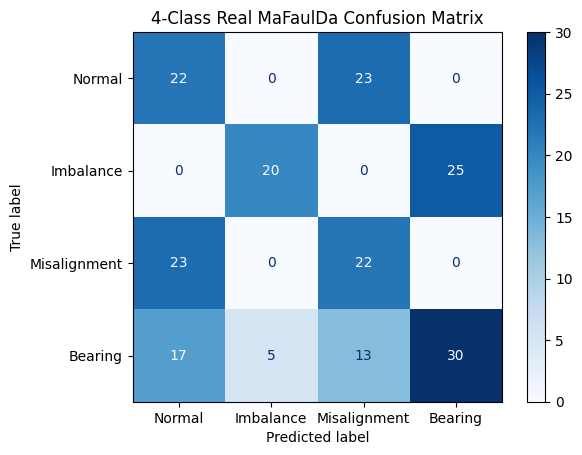

In [83]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred_4c = np.argmax(model_4class.predict(Xv_test_fft_4c), axis=1)
cm = confusion_matrix(y_test_4c, y_pred_4c)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap='Blues')
plt.title('4-Class Real MaFaulDa Confusion Matrix')
plt.show()

(array([0, 1, 2, 3]), array([180, 180, 180, 275]))
(array([0, 1, 2, 3]), array([45, 45, 45, 65]))


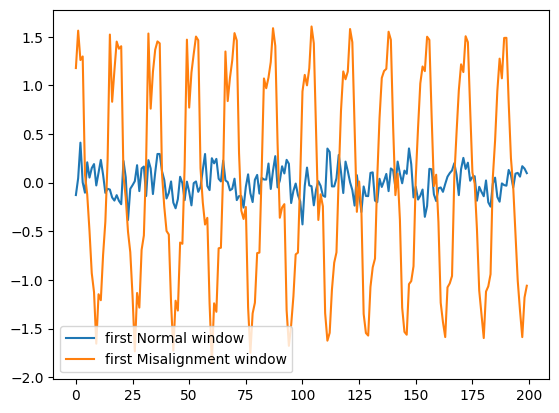

In [84]:
print(np.unique(y_train_4c, return_counts=True))
print(np.unique(y_test_4c, return_counts=True))
# spot-check: does a Misalignment file's decimated signal actually look different from Normal's?
import matplotlib.pyplot as plt
plt.plot(Xv_train_4c[0][:200], label='first Normal window')
plt.plot(Xv_train_4c[181][:200], label='first Misalignment window')  # index just past Normal's 180
plt.legend(); plt.show()

In [85]:
# Fix the bearing over-count from before, keep everything else the same
def collect_files(pattern, cap, seed=42):
    files = glob.glob(pattern, recursive=True)
    rng = np.random.default_rng(seed)
    if len(files) > cap:
        files = list(rng.choice(files, size=cap, replace=False))
    return files

normal_files = collect_files(os.path.join(base, 'normal', '*.csv'), cap=45)
imbalance_files = collect_files(os.path.join(base, 'imbalance', '**', '*.csv'), cap=45)
misalignment_files = collect_files(os.path.join(base, '*misalignment', '**', '*.csv'), cap=45)
bearing_files = collect_files(os.path.join(base, 'underhang', '**', '*.csv'), cap=23) + \
                collect_files(os.path.join(base, 'overhang', '**', '*.csv'), cap=22)

print(f"Normal: {len(normal_files)}, Imbalance: {len(imbalance_files)}, "
      f"Misalignment: {len(misalignment_files)}, Bearing: {len(bearing_files)}")

Normal: 45, Imbalance: 45, Misalignment: 45, Bearing: 45


In [86]:
class_names = ['Normal', 'Imbalance', 'Misalignment', 'Bearing']
all_files_by_class = [normal_files, imbalance_files, misalignment_files, bearing_files]

train_files_by_class, test_files_by_class = [], []
for files in all_files_by_class:
    tr, te = split_files(files)
    train_files_by_class.append(tr)
    test_files_by_class.append(te)

Xv_train_list, y_train_list, Xv_test_list, y_test_list = [], [], [], []
for label, (tr, te) in enumerate(zip(train_files_by_class, test_files_by_class)):
    Xv_tr, y_tr = load_windows(tr, label)
    Xv_te, y_te = load_windows(te, label)
    Xv_train_list.append(Xv_tr); y_train_list.append(y_tr)
    Xv_test_list.append(Xv_te); y_test_list.append(y_te)
    print(f"{class_names[label]}: {len(y_tr)} train, {len(y_te)} test")

Xv_train_4c = np.concatenate(Xv_train_list)
y_train_4c = np.concatenate(y_train_list)
Xv_test_4c = np.concatenate(Xv_test_list)
y_test_4c = np.concatenate(y_test_list)
print(f"Balance check — train: {np.bincount(y_train_4c)}, test: {np.bincount(y_test_4c)}")

Normal: 180 train, 45 test
Imbalance: 180 train, 45 test
Misalignment: 180 train, 45 test
Bearing: 180 train, 45 test
Balance check — train: [180 180 180 180], test: [45 45 45 45]


In [87]:
def compute_fft_batch(X, n_bins=256):
    return np.array([np.abs(np.fft.rfft(sig))[:n_bins] / len(sig) for sig in X])

Xv_train_fft_4c = compute_fft_batch(Xv_train_4c).reshape((-1, 256, 1))
Xv_test_fft_4c = compute_fft_batch(Xv_test_4c).reshape((-1, 256, 1))

model_4class_v2 = models.Sequential([
    layers.Conv1D(16, 5, activation='relu', input_shape=(256, 1)),
    layers.MaxPooling1D(2),
    layers.Conv1D(32, 3, activation='relu'),
    layers.MaxPooling1D(2),
    layers.Conv1D(32, 3, activation='relu'),
    layers.MaxPooling1D(2),
    layers.Flatten(),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(4, activation='softmax')
])
model_4class_v2.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_4c_v2 = model_4class_v2.fit(Xv_train_fft_4c, y_train_4c, epochs=30, batch_size=16,
                                  validation_data=(Xv_test_fft_4c, y_test_4c), verbose=1)
print(f"4-class v2 float32 accuracy: {model_4class_v2.evaluate(Xv_test_fft_4c, y_test_4c, verbose=0)[1]:.3f}")

Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.3028 - loss: 1.3727 - val_accuracy: 0.5000 - val_loss: 1.3249
Epoch 2/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4389 - loss: 1.1917 - val_accuracy: 0.5278 - val_loss: 1.0425
Epoch 3/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5000 - loss: 1.0064 - val_accuracy: 0.5500 - val_loss: 0.9687
Epoch 4/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5472 - loss: 0.9443 - val_accuracy: 0.5889 - val_loss: 0.9107
Epoch 5/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5431 - loss: 0.9062 - val_accuracy: 0.5333 - val_loss: 0.8850
Epoch 6/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5514 - loss: 0.8749 - val_accuracy: 0.5444 - val_loss: 0.8633
Epoch 7/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5806 - loss: 0.8644 - val_accuracy: 0.5167 - val_loss: 0.8552
Epoch 8/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6139 - loss: 0.8459 - val_accuracy: 0.5389 - val_loss: 0.

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
[[30  0 10  5]
 [ 5 25  5 10]
 [13  0 32  0]
 [13  0  0 32]]


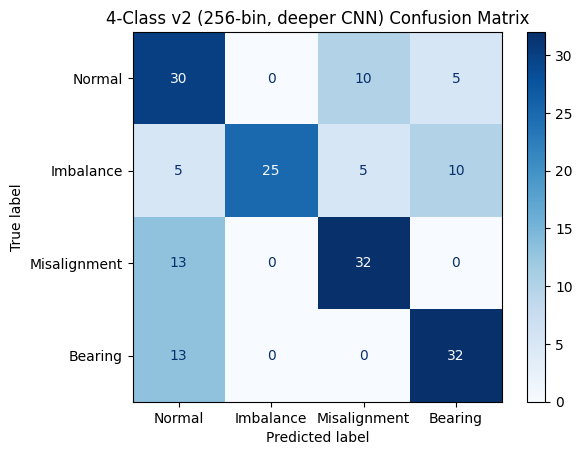

In [88]:
y_pred_4c_v2 = np.argmax(model_4class_v2.predict(Xv_test_fft_4c), axis=1)
cm2 = confusion_matrix(y_test_4c, y_pred_4c_v2)
print(cm2)
ConfusionMatrixDisplay(cm2, display_labels=class_names).plot(cmap='Blues')
plt.title('4-Class v2 (256-bin, deeper CNN) Confusion Matrix')
plt.show()

In [89]:
def representative_dataset_4c():
    idx = np.random.permutation(len(Xv_train_fft_4c))[:200]
    for i in idx:
        yield [Xv_train_fft_4c[i:i+1].astype(np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(model_4class_v2)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset_4c
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_4class = converter.convert()
print(f"4-class quantized size: {len(tflite_4class)/1024:.2f} KB")

with open('model_4class.tflite', 'wb') as f:
    f.write(tflite_4class)

Saved artifact at '/tmp/tmpgbo0qe1x'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 1), dtype=tf.float32, name='keras_tensor_106')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  134804633957776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806649763792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806649763600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134806649750352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804039212432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804039208016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804039207824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804039205712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804039205904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134804039207632: TensorSpec(shape=(), dtype=tf.resource, name=None)


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


4-class quantized size: 46.65 KB


In [90]:
interpreter = tf.lite.Interpreter(model_content=tflite_4class)
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()
in_scale, in_zero = input_details[0]['quantization']

correct = 0
for i in range(len(Xv_test_fft_4c)):
    x = Xv_test_fft_4c[i:i+1]
    x_q = (x / in_scale + in_zero).astype(np.int8)
    interpreter.set_tensor(input_details[0]['index'], x_q)
    interpreter.invoke()
    pred = np.argmax(interpreter.get_tensor(output_details[0]['index']))
    if pred == y_test_4c[i]:
        correct += 1
print(f"4-class int8 accuracy: {correct/len(y_test_4c):.3f}")

4-class int8 accuracy: 0.394


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [91]:
def convert_to_c_array(tflite_path, header_path, var_name="model_data"):
    with open(tflite_path, "rb") as f:
        data = f.read()
    with open(header_path, "w") as f:
        f.write(f"const unsigned char {var_name}[] = {{\n")
        for i, b in enumerate(data):
            f.write(f"0x{b:02x}, ")
            if (i + 1) % 12 == 0:
                f.write("\n")
        f.write(f"\n}};\nconst unsigned int {var_name}_len = {len(data)};\n")

convert_to_c_array("model_4class.tflite", "model_4class_data.h", "aerator_model")
print("Header generated, first 300 chars:")
print(open("model_4class_data.h").read()[:300])

Header generated, first 300 chars:
const unsigned char aerator_model[] = {
0x20, 0x00, 0x00, 0x00, 0x54, 0x46, 0x4c, 0x33, 0x00, 0x00, 0x00, 0x00, 
0x14, 0x00, 0x20, 0x00, 0x1c, 0x00, 0x18, 0x00, 0x14, 0x00, 0x10, 0x00, 
0x0c, 0x00, 0x00, 0x00, 0x08, 0x00, 0x04, 0x00, 0x14, 0x00, 0x00, 0x00, 
0x1c, 0x00, 0x00, 0x00, 0x90, 0x00, 0x00,


In [92]:
import time

interpreter = tf.lite.Interpreter(model_content=tflite_4class)
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()
in_scale, in_zero = input_details[0]['quantization']

x = Xv_test_fft_4c[0:1]
x_q = (x / in_scale + in_zero).astype(np.int8)

# Warm-up
for _ in range(5):
    interpreter.set_tensor(input_details[0]['index'], x_q)
    interpreter.invoke()

n_runs = 200
start = time.perf_counter()
for _ in range(n_runs):
    interpreter.set_tensor(input_details[0]['index'], x_q)
    interpreter.invoke()
end = time.perf_counter()

avg_ms = (end - start) / n_runs * 1000
print(f"Avg inference time on Colab CPU: {avg_ms:.3f} ms")
print(f"Model arena size (tensors): {interpreter.get_tensor_details()}")

Avg inference time on Colab CPU: 0.067 ms
Model arena size (tensors): [{'name': 'serving_default_keras_tensor_106:0', 'index': 0, 'shape': array([  1, 256,   1], dtype=int32), 'shape_signature': array([ -1, 256,   1], dtype=int32), 'dtype': <class 'numpy.int8'>, 'quantization': (0.0059319850988686085, -128), 'quantization_parameters': {'scales': array([0.00593199], dtype=float32), 'zero_points': array([-128], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}, {'name': 'arith.constant', 'index': 1, 'shape': array([], dtype=int32), 'shape_signature': array([], dtype=int32), 'dtype': <class 'numpy.int32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}, {'name': 'arith.constant1', 'index': 2, 'shape': array([3], dtype=int32), 'shape_signature': array([3], dtype=int32), 'dtype': <class 'numpy.int32'>, 'quantization': (0.0, 0), 'quantizati

In [93]:
def energy_trigger(window, threshold):
    """Simple RMS-energy-based wake trigger: only run full inference if energy exceeds threshold."""
    rms = np.sqrt(np.mean(window**2))
    return rms > threshold

# Estimate a sensible threshold from real Normal windows (calibration)
normal_test_windows = Xv_test_4c[y_test_4c == 0]
normal_rms = np.sqrt(np.mean(normal_test_windows**2, axis=1))
print(f"Normal RMS: mean={normal_rms.mean():.4f}, std={normal_rms.std():.4f}, max={normal_rms.max():.4f}")

threshold = normal_rms.mean() + 3 * normal_rms.std()
print(f"Proposed wake threshold: {threshold:.4f}")

# Simulate: how many windows would trigger full inference, per class?
for label, name in enumerate(class_names):
    windows = Xv_test_4c[y_test_4c == label]
    rms_vals = np.sqrt(np.mean(windows**2, axis=1))
    triggered = np.sum(rms_vals > threshold)
    print(f"{name}: {triggered}/{len(windows)} windows would trigger full inference ({100*triggered/len(windows):.1f}%)")

Normal RMS: mean=0.2025, std=0.0635, max=0.2968
Proposed wake threshold: 0.3931
Normal: 0/45 windows would trigger full inference (0.0%)
Imbalance: 30/45 windows would trigger full inference (66.7%)
Misalignment: 0/45 windows would trigger full inference (0.0%)
Bearing: 25/45 windows would trigger full inference (55.6%)


In [94]:
def spectral_trigger_score(window, fs=1000):
    fft_mag = np.abs(np.fft.rfft(window))
    freqs = np.fft.rfftfreq(len(window), 1/fs)
    # ratio of energy near 2x rotational frequency (misalignment signature) to total energy
    band = (freqs > 90) & (freqs < 110)  # adjust based on your motor's known 2x harmonic
    return fft_mag[band].sum() / (fft_mag.sum() + 1e-9)

for label, name in enumerate(class_names):
    windows = Xv_test_4c[y_test_4c == label]
    scores = np.array([spectral_trigger_score(w) for w in windows])
    print(f"{name}: mean spectral score={scores.mean():.4f}, std={scores.std():.4f}")

Normal: mean spectral score=0.0251, std=0.0123
Imbalance: mean spectral score=0.0264, std=0.0055
Misalignment: mean spectral score=0.0243, std=0.0148
Bearing: mean spectral score=0.0266, std=0.0130


Normal: dominant peak at 48.0 Hz, magnitude 0.0247
Imbalance: dominant peak at 56.0 Hz, magnitude 0.1669
Misalignment: dominant peak at 59.0 Hz, magnitude 0.0159
Bearing: dominant peak at 24.0 Hz, magnitude 0.1231


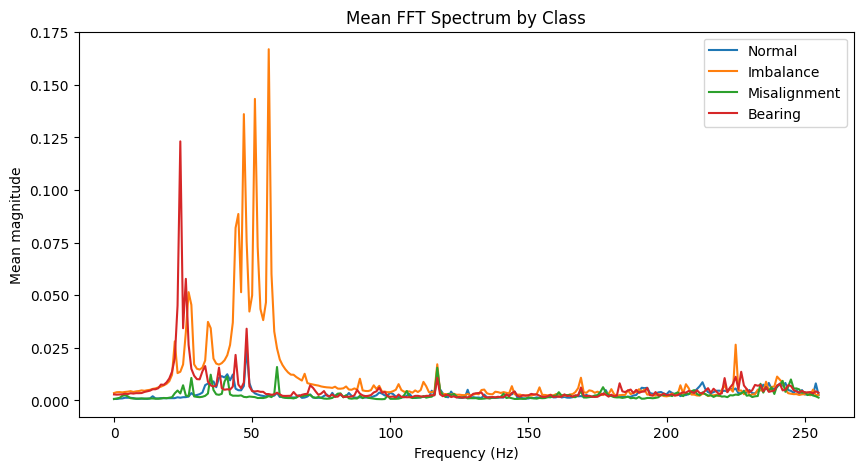

In [95]:
def compute_fft_batch(X, n_bins=256):
    return np.array([np.abs(np.fft.rfft(sig))[:n_bins] / len(sig) for sig in X])

freqs = np.fft.rfftfreq(window_size, 1/1000)[:256]  # your decimated fs=1000

Xv_test_fft_full = compute_fft_batch(Xv_test_4c, n_bins=256)

for label, name in enumerate(class_names):
    class_fft = Xv_test_fft_full[y_test_4c == label]
    mean_spectrum = class_fft.mean(axis=0)
    peak_idx = np.argmax(mean_spectrum[2:]) + 2  # skip DC bin
    print(f"{name}: dominant peak at {freqs[peak_idx]:.1f} Hz, magnitude {mean_spectrum[peak_idx]:.4f}")

# Plot mean spectrum per class to see it directly
plt.figure(figsize=(10,5))
for label, name in enumerate(class_names):
    class_fft = Xv_test_fft_full[y_test_4c == label]
    plt.plot(freqs, class_fft.mean(axis=0), label=name)
plt.xlabel('Frequency (Hz)'); plt.ylabel('Mean magnitude'); plt.legend(); plt.title('Mean FFT Spectrum by Class')
plt.show()

In [96]:
def peakiness(window_fft):
    return window_fft.max() / (window_fft.mean() + 1e-9)

for label, name in enumerate(class_names):
    class_fft = Xv_test_fft_full[y_test_4c == label]
    scores = np.array([peakiness(w) for w in class_fft])
    print(f"{name}: peakiness mean={scores.mean():.2f}, std={scores.std():.2f}, min={scores.min():.2f}, max={scores.max():.2f}")

Normal: peakiness mean=18.57, std=6.84, min=10.53, max=34.11
Imbalance: peakiness mean=55.49, std=15.15, min=29.59, max=82.14
Misalignment: peakiness mean=24.35, std=10.49, min=9.87, max=47.46
Bearing: peakiness mean=36.22, std=23.98, min=4.76, max=81.02


In [97]:
def harmonic_ratio(window, fs=1000):
    fft_mag = np.abs(np.fft.rfft(window))
    freqs = np.fft.rfftfreq(len(window), 1/fs)
    # find fundamental (1x) as the dominant peak in a plausible motor-speed range
    search_band = (freqs > 15) & (freqs < 70)
    f1_idx = np.argmax(fft_mag[search_band]) + np.argmax(search_band)
    f1 = freqs[f1_idx]
    f1_mag = fft_mag[f1_idx]
    # find magnitude nearest 2x that frequency
    f2_target = 2 * f1
    f2_idx = np.argmin(np.abs(freqs - f2_target))
    f2_mag = fft_mag[f2_idx]
    return f2_mag / (f1_mag + 1e-9), f1

for label, name in enumerate(class_names):
    windows = Xv_test_4c[y_test_4c == label]
    ratios, f1s = zip(*[harmonic_ratio(w) for w in windows])
    ratios = np.array(ratios)
    print(f"{name}: 2x/1x ratio mean={ratios.mean():.3f}, std={ratios.std():.3f}, mean f1={np.mean(f1s):.1f} Hz")

Normal: 2x/1x ratio mean=0.134, std=0.122, mean f1=39.4 Hz
Imbalance: 2x/1x ratio mean=0.040, std=0.028, mean f1=39.8 Hz
Misalignment: 2x/1x ratio mean=0.196, std=0.100, mean f1=34.2 Hz
Bearing: 2x/1x ratio mean=0.149, std=0.137, mean f1=34.4 Hz


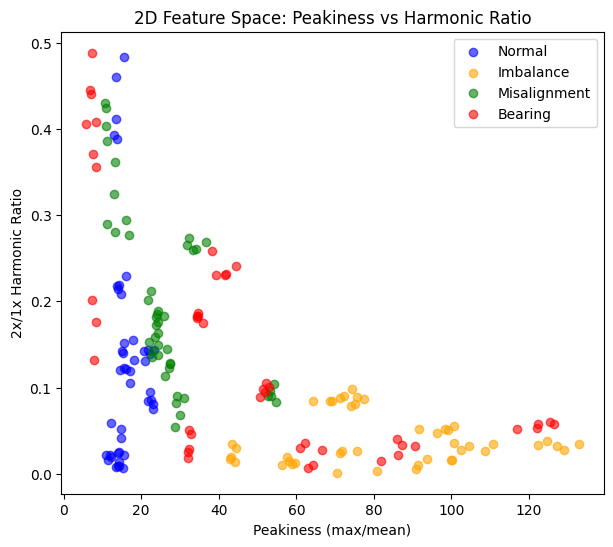

2-feature logistic regression accuracy: 0.628


In [98]:
def two_features(window, fs=1000):
    fft_mag = np.abs(np.fft.rfft(window))
    freqs = np.fft.rfftfreq(len(window), 1/fs)
    peak = fft_mag.max() / (fft_mag.mean() + 1e-9)
    search_band = (freqs > 15) & (freqs < 70)
    f1_idx = np.argmax(fft_mag[search_band]) + np.argmax(search_band)
    f1_mag = fft_mag[f1_idx]
    f2_idx = np.argmin(np.abs(freqs - 2*freqs[f1_idx]))
    f2_mag = fft_mag[f2_idx]
    ratio = f2_mag / (f1_mag + 1e-9)
    return peak, ratio

feats = {name: [] for name in class_names}
for label, name in enumerate(class_names):
    windows = Xv_test_4c[y_test_4c == label]
    feats[name] = np.array([two_features(w) for w in windows])

plt.figure(figsize=(7,6))
colors = {'Normal':'blue','Imbalance':'orange','Misalignment':'green','Bearing':'red'}
for name in class_names:
    plt.scatter(feats[name][:,0], feats[name][:,1], label=name, alpha=0.6, color=colors[name])
plt.xlabel('Peakiness (max/mean)'); plt.ylabel('2x/1x Harmonic Ratio'); plt.legend()
plt.title('2D Feature Space: Peakiness vs Harmonic Ratio')
plt.show()

# Quick quantitative check: simple logistic regression on just these 2 features
from sklearn.linear_model import LogisticRegression
X_2feat = np.vstack([feats[name] for name in class_names])
y_2feat = np.concatenate([[i]*len(feats[name]) for i, name in enumerate(class_names)])
clf = LogisticRegression(max_iter=1000).fit(X_2feat, y_2feat)
print(f"2-feature logistic regression accuracy: {clf.score(X_2feat, y_2feat):.3f}")

In [1]:
def two_stage_features(window, fs=1000):
    fft_mag = np.abs(np.fft.rfft(window))
    freqs = np.fft.rfftfreq(len(window), 1/fs)
    peak = fft_mag.max() / (fft_mag.mean() + 1e-9)
    search_band = (freqs > 15) & (freqs < 70)
    f1_idx = np.argmax(fft_mag[search_band]) + np.argmax(search_band)
    f1_mag = fft_mag[f1_idx]
    f2_idx = np.argmin(np.abs(freqs - 2*freqs[f1_idx]))
    f2_mag = fft_mag[f2_idx]
    ratio = f2_mag / (f1_mag + 1e-9)
    return peak, ratio

# Calibrate the gate from TRAIN data only (Normal class), never test data
normal_train_windows = Xv_train_4c[y_train_4c == 0]
normal_feats = np.array([two_stage_features(w) for w in normal_train_windows])
peak_mean, peak_std = normal_feats[:,0].mean(), normal_feats[:,0].std()
ratio_mean, ratio_std = normal_feats[:,1].mean(), normal_feats[:,1].std()

# Gate: wake (run full CNN) if EITHER feature deviates from Normal's calibrated range
N_SIGMA = 2.0
def should_wake(peak, ratio):
    peak_dev = abs(peak - peak_mean) > N_SIGMA * peak_std
    ratio_dev = abs(ratio - ratio_mean) > N_SIGMA * ratio_std
    return peak_dev or ratio_dev

# Run the full two-stage system on the TEST set
Xv_test_fft_4c = compute_fft_batch(Xv_test_4c, n_bins=256)  # reuse if already computed

woke_up = []
final_preds = []
for i, window in enumerate(Xv_test_4c):
    peak, ratio = two_stage_features(window)
    if should_wake(peak, ratio):
        woke_up.append(True)
        x = Xv_test_fft_4c[i:i+1].reshape(1, 256, 1)
        pred = np.argmax(model_4class_v2.predict(x, verbose=0), axis=1)[0]
        final_preds.append(pred)
    else:
        woke_up.append(False)
        final_preds.append(0)  # assume Normal when the gate stays asleep

woke_up = np.array(woke_up)
final_preds = np.array(final_preds)

overall_acc = (final_preds == y_test_4c).mean()
wake_rate = woke_up.mean()

print(f"Overall system accuracy (gate + CNN combined): {overall_acc:.3f}")
print(f"Fraction of windows that triggered full inference: {wake_rate:.3f}")
print(f"Fraction of windows that skipped full inference (power saved): {1-wake_rate:.3f}")

print("\nPer-class wake rate (should be low for Normal, high for faults):")
for label, name in enumerate(class_names):
    mask = y_test_4c == label
    print(f"  {name}: {woke_up[mask].mean():.3f} wake rate, "
          f"accuracy when awake: {(final_preds[mask]==label)[woke_up[mask]].mean() if woke_up[mask].any() else float('nan'):.3f}")

NameError: name 'Xv_train_4c' is not defined

In [2]:
for name in ['Xv_train_4c', 'y_train_4c', 'Xv_test_4c', 'y_test_4c', 'model_4class_v2', 'class_names', 'path']:
    print(name, name in dir())

Xv_train_4c False
y_train_4c False
Xv_test_4c False
y_test_4c False
model_4class_v2 False
class_names False
path False


In [3]:
from google.colab import userdata
import os
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
print("Credentials loaded")

Credentials loaded


In [4]:
import kagglehub
path = kagglehub.dataset_download("vuxuancu/mafaulda-full")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mafaulda-full' dataset.
Path to dataset files: /kaggle/input/mafaulda-full


In [5]:
import glob, os
import numpy as np
import pandas as pd
from scipy.signal import decimate
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

tf.random.set_seed(42)
np.random.seed(42)
import random
random.seed(42)
os.environ['PYTHONHASHSEED'] = '42'

original_fs = 50000
fs = 1000
decim_factor = original_fs // fs
window_size = fs

base = os.path.join(path, 'mafaulda')

In [6]:
def collect_files(pattern, cap, seed=42):
    files = glob.glob(pattern, recursive=True)
    rng = np.random.default_rng(seed)
    if len(files) > cap:
        files = list(rng.choice(files, size=cap, replace=False))
    return files

normal_files = collect_files(os.path.join(base, 'normal', '*.csv'), cap=45)
imbalance_files = collect_files(os.path.join(base, 'imbalance', '**', '*.csv'), cap=45)
misalignment_files = collect_files(os.path.join(base, '*misalignment', '**', '*.csv'), cap=45)
bearing_files = collect_files(os.path.join(base, 'underhang', '**', '*.csv'), cap=23) + \
                collect_files(os.path.join(base, 'overhang', '**', '*.csv'), cap=22)

print(f"Normal: {len(normal_files)}, Imbalance: {len(imbalance_files)}, "
      f"Misalignment: {len(misalignment_files)}, Bearing: {len(bearing_files)}")

Normal: 45, Imbalance: 45, Misalignment: 45, Bearing: 45


In [7]:
class_names = ['Normal', 'Imbalance', 'Misalignment', 'Bearing']
all_files_by_class = [normal_files, imbalance_files, misalignment_files, bearing_files]

def split_files(files, test_frac=0.2, seed=42):
    files = list(files)
    rng = np.random.default_rng(seed)
    rng.shuffle(files)
    n_test = int(len(files) * test_frac)
    return files[n_test:], files[:n_test]

def load_windows(files, label, col_vib=2):
    X, y = [], []
    for f in files:
        df = pd.read_csv(f, header=None)
        vib = decimate(df.iloc[:, col_vib].values, decim_factor, ftype='iir', zero_phase=True)
        n_windows = len(vib) // window_size
        for i in range(n_windows):
            X.append(vib[i*window_size:(i+1)*window_size])
            y.append(label)
    return np.array(X), np.array(y)

train_files_by_class, test_files_by_class = [], []
for files in all_files_by_class:
    tr, te = split_files(files)
    train_files_by_class.append(tr)
    test_files_by_class.append(te)

Xv_train_list, y_train_list, Xv_test_list, y_test_list = [], [], [], []
for label, (tr, te) in enumerate(zip(train_files_by_class, test_files_by_class)):
    Xv_tr, y_tr = load_windows(tr, label)
    Xv_te, y_te = load_windows(te, label)
    Xv_train_list.append(Xv_tr); y_train_list.append(y_tr)
    Xv_test_list.append(Xv_te); y_test_list.append(y_te)
    print(f"{class_names[label]}: {len(y_tr)} train, {len(y_te)} test")

Xv_train_4c = np.concatenate(Xv_train_list)
y_train_4c = np.concatenate(y_train_list)
Xv_test_4c = np.concatenate(Xv_test_list)
y_test_4c = np.concatenate(y_test_list)
print(f"Balance — train: {np.bincount(y_train_4c)}, test: {np.bincount(y_test_4c)}")

Normal: 180 train, 45 test
Imbalance: 180 train, 45 test
Misalignment: 180 train, 45 test
Bearing: 180 train, 45 test
Balance — train: [180 180 180 180], test: [45 45 45 45]


In [8]:
def compute_fft_batch(X, n_bins=256):
    return np.array([np.abs(np.fft.rfft(sig))[:n_bins] / len(sig) for sig in X])

Xv_train_fft_4c = compute_fft_batch(Xv_train_4c).reshape((-1, 256, 1))
Xv_test_fft_4c = compute_fft_batch(Xv_test_4c).reshape((-1, 256, 1))

model_4class_v2 = models.Sequential([
    layers.Conv1D(16, 5, activation='relu', input_shape=(256, 1)),
    layers.MaxPooling1D(2),
    layers.Conv1D(32, 3, activation='relu'),
    layers.MaxPooling1D(2),
    layers.Conv1D(32, 3, activation='relu'),
    layers.MaxPooling1D(2),
    layers.Flatten(),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(4, activation='softmax')
])
model_4class_v2.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_4class_v2.fit(Xv_train_fft_4c, y_train_4c, epochs=30, batch_size=16,
                     validation_data=(Xv_test_fft_4c, y_test_4c), verbose=1)
print(f"4-class v2 accuracy: {model_4class_v2.evaluate(Xv_test_fft_4c, y_test_4c, verbose=0)[1]:.3f}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.2958 - loss: 1.3737 - val_accuracy: 0.5056 - val_loss: 1.3163
Epoch 2/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4667 - loss: 1.1925 - val_accuracy: 0.4889 - val_loss: 1.0071
Epoch 3/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5278 - loss: 1.0199 - val_accuracy: 0.5500 - val_loss: 0.9467
Epoch 4/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5861 - loss: 0.9503 - val_accuracy: 0.5333 - val_loss: 0.9434
Epoch 5/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5986 - loss: 0.8976 - val_accuracy: 0.4722 - val_loss: 0.9275
Epoch 6/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6153 - loss: 0.8753 - val_accuracy: 0.4278 - val_loss: 0.9383
Epoch 7/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6514 - loss: 0.8216 - val_accuracy: 0.4111 - val_loss: 0.9824
Epoch 8/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6639 - loss: 0.7681 - val_accuracy: 0.4778 - val_loss

In [9]:
def two_stage_features(window, fs=1000):
    fft_mag = np.abs(np.fft.rfft(window))
    freqs = np.fft.rfftfreq(len(window), 1/fs)
    peak = fft_mag.max() / (fft_mag.mean() + 1e-9)
    search_band = (freqs > 15) & (freqs < 70)
    f1_idx = np.argmax(fft_mag[search_band]) + np.argmax(search_band)
    f1_mag = fft_mag[f1_idx]
    f2_idx = np.argmin(np.abs(freqs - 2*freqs[f1_idx]))
    f2_mag = fft_mag[f2_idx]
    ratio = f2_mag / (f1_mag + 1e-9)
    return peak, ratio

# Calibrate the gate from TRAIN data only (Normal class), never test data
normal_train_windows = Xv_train_4c[y_train_4c == 0]
normal_feats = np.array([two_stage_features(w) for w in normal_train_windows])
peak_mean, peak_std = normal_feats[:,0].mean(), normal_feats[:,0].std()
ratio_mean, ratio_std = normal_feats[:,1].mean(), normal_feats[:,1].std()

N_SIGMA = 2.0
def should_wake(peak, ratio):
    peak_dev = abs(peak - peak_mean) > N_SIGMA * peak_std
    ratio_dev = abs(ratio - ratio_mean) > N_SIGMA * ratio_std
    return peak_dev or ratio_dev

woke_up = []
final_preds = []
for i, window in enumerate(Xv_test_4c):
    peak, ratio = two_stage_features(window)
    if should_wake(peak, ratio):
        woke_up.append(True)
        x = Xv_test_fft_4c[i:i+1].reshape(1, 256, 1)
        pred = np.argmax(model_4class_v2.predict(x, verbose=0), axis=1)[0]
        final_preds.append(pred)
    else:
        woke_up.append(False)
        final_preds.append(0)  # gate stayed asleep -> implicitly reported as Normal

woke_up = np.array(woke_up)
final_preds = np.array(final_preds)

overall_acc = (final_preds == y_test_4c).mean()
wake_rate = woke_up.mean()

print(f"Overall system accuracy (gate + CNN combined): {overall_acc:.3f}")
print(f"Fraction of windows that triggered full inference: {wake_rate:.3f}")
print(f"Fraction of windows that skipped full inference (power saved): {1-wake_rate:.3f}")

print("\nPer-class wake rate:")
for label, name in enumerate(class_names):
    mask = y_test_4c == label
    awake_mask = woke_up[mask]
    acc_when_awake = (final_preds[mask] == label)[awake_mask].mean() if awake_mask.any() else float('nan')
    print(f"  {name}: wake rate={woke_up[mask].mean():.3f}, accuracy when awake={acc_when_awake:.3f}")

Overall system accuracy (gate + CNN combined): 0.611
Fraction of windows that triggered full inference: 0.572
Fraction of windows that skipped full inference (power saved): 0.428

Per-class wake rate:
  Normal: wake rate=0.244, accuracy when awake=0.636
  Imbalance: wake rate=0.889, accuracy when awake=0.750
  Misalignment: wake rate=0.400, accuracy when awake=0.667
  Bearing: wake rate=0.756, accuracy when awake=0.794


In [10]:
def two_stage_features_128(window, fs=1000):
    fft_mag = np.abs(np.fft.rfft(window))
    freqs = np.fft.rfftfreq(len(window), 1/fs)
    peak = fft_mag.max() / (fft_mag.mean() + 1e-9)
    search_band = (freqs > 15) & (freqs < 70)
    f1_idx = np.argmax(fft_mag[search_band]) + np.argmax(search_band)
    f1_mag = fft_mag[f1_idx]
    f2_idx = np.argmin(np.abs(freqs - 2*freqs[f1_idx]))
    f2_mag = fft_mag[f2_idx]
    ratio = f2_mag / (f1_mag + 1e-9)
    return peak, ratio

# Use the 2-class deployed model's own Normal-class TRAINING windows (Xv_train, y_train==0)
normal_train_128 = Xv_train[y_train == 0]
feats_128 = np.array([two_stage_features_128(w) for w in normal_train_128])

peak_mean, peak_std = feats_128[:,0].mean(), feats_128[:,0].std()
ratio_mean, ratio_std = feats_128[:,1].mean(), feats_128[:,1].std()

N_SIGMA = 2.0
peak_threshold = peak_mean + N_SIGMA * peak_std
ratio_low = max(0, ratio_mean - N_SIGMA * ratio_std)
ratio_high = ratio_mean + N_SIGMA * ratio_std

print(f"Normal peakiness: mean={peak_mean:.2f}, std={peak_std:.2f}")
print(f"Normal 2x/1x ratio: mean={ratio_mean:.4f}, std={ratio_std:.4f}")
print(f"\n=== COPY THESE INTO the .ino ===")
print(f"#define PEAKINESS_WAKE_THRESHOLD     {peak_threshold:.2f}f")
print(f"#define HARMONIC_RATIO_LOW           {ratio_low:.4f}f")
print(f"#define HARMONIC_RATIO_HIGH          {ratio_high:.4f}f")

# Sanity check: how do the other class's windows (Imbalance) score against these?
imbalance_train_128 = Xv_train[y_train == 1]
feats_imb = np.array([two_stage_features_128(w) for w in imbalance_train_128])
wake_rate = ((feats_imb[:,0] > peak_threshold) | (feats_imb[:,1] < ratio_low) | (feats_imb[:,1] > ratio_high)).mean()
print(f"\nSanity check — Imbalance wake rate with these thresholds: {wake_rate:.3f} (should be high, ideally >0.7)")

NameError: name 'Xv_train' is not defined

In [11]:
for name in ['Xv_train_4c', 'y_train_4c', 'Xv_test_4c', 'y_test_4c', 'model_4class_v2',
             'Xv_train', 'y_train', 'Xv_test', 'y_test', 'model_small', 'tflite_small', 'path']:
    print(name, name in dir())

Xv_train_4c True
y_train_4c True
Xv_test_4c True
y_test_4c True
model_4class_v2 True
Xv_train False
y_train False
Xv_test False
y_test False
model_small False
tflite_small False
path True


In [12]:
import glob, os
import numpy as np
import pandas as pd
from scipy.signal import decimate

# Redefine in case these got overwritten by the 4-class work
original_fs = 50000
fs = 1000
decim_factor = original_fs // fs
window_size = fs
base = os.path.join(path, 'mafaulda')

normal_files = glob.glob(os.path.join(base, 'normal', '*.csv'))
imbalance_files = glob.glob(os.path.join(base, 'imbalance', '**', '*.csv'), recursive=True)

rng = np.random.default_rng(42)
imbalance_files = list(rng.choice(imbalance_files, size=min(len(imbalance_files), 60), replace=False))

def split_files(files, test_frac=0.2, seed=42):
    files = list(files)
    r = np.random.default_rng(seed)
    r.shuffle(files)
    n_test = int(len(files) * test_frac)
    return files[n_test:], files[:n_test]

normal_train_f, normal_test_f = split_files(normal_files)
imb_train_f, imb_test_f = split_files(imbalance_files)

def load_windows(files, label, col_vib=2):
    X, y = [], []
    for f in files:
        df = pd.read_csv(f, header=None)
        vib = decimate(df.iloc[:, col_vib].values, decim_factor, ftype='iir', zero_phase=True)
        n_windows = len(vib) // window_size
        for i in range(n_windows):
            X.append(vib[i*window_size:(i+1)*window_size])
            y.append(label)
    return np.array(X), np.array(y)

Xv_train_n, y_train_n = load_windows(normal_train_f, 0)
Xv_train_i, y_train_i = load_windows(imb_train_f, 1)
Xv_test_n, y_test_n = load_windows(normal_test_f, 0)
Xv_test_i, y_test_i = load_windows(imb_test_f, 1)

Xv_train = np.concatenate([Xv_train_n, Xv_train_i])
y_train = np.concatenate([y_train_n, y_train_i])
Xv_test = np.concatenate([Xv_test_n, Xv_test_i])
y_test = np.concatenate([y_test_n, y_test_i])

print(f"Train: {len(y_train)} windows, Test: {len(y_test)} windows")
print(f"Train balance: {np.bincount(y_train)}, Test balance: {np.bincount(y_test)}")

Train: 440 windows, Test: 105 windows
Train balance: [200 240], Test balance: [45 60]


In [13]:
def two_stage_features_128(window, fs=1000):
    fft_mag = np.abs(np.fft.rfft(window))
    freqs = np.fft.rfftfreq(len(window), 1/fs)
    peak = fft_mag.max() / (fft_mag.mean() + 1e-9)
    search_band = (freqs > 15) & (freqs < 70)
    f1_idx = np.argmax(fft_mag[search_band]) + np.argmax(search_band)
    f1_mag = fft_mag[f1_idx]
    f2_idx = np.argmin(np.abs(freqs - 2*freqs[f1_idx]))
    f2_mag = fft_mag[f2_idx]
    ratio = f2_mag / (f1_mag + 1e-9)
    return peak, ratio

# Use the 2-class deployed model's own Normal-class TRAINING windows (Xv_train, y_train==0)
normal_train_128 = Xv_train[y_train == 0]
feats_128 = np.array([two_stage_features_128(w) for w in normal_train_128])

peak_mean, peak_std = feats_128[:,0].mean(), feats_128[:,0].std()
ratio_mean, ratio_std = feats_128[:,1].mean(), feats_128[:,1].std()

N_SIGMA = 2.0
peak_threshold = peak_mean + N_SIGMA * peak_std
ratio_low = max(0, ratio_mean - N_SIGMA * ratio_std)
ratio_high = ratio_mean + N_SIGMA * ratio_std

print(f"Normal peakiness: mean={peak_mean:.2f}, std={peak_std:.2f}")
print(f"Normal 2x/1x ratio: mean={ratio_mean:.4f}, std={ratio_std:.4f}")
print(f"\n=== COPY THESE INTO the .ino ===")
print(f"#define PEAKINESS_WAKE_THRESHOLD     {peak_threshold:.2f}f")
print(f"#define HARMONIC_RATIO_LOW           {ratio_low:.4f}f")
print(f"#define HARMONIC_RATIO_HIGH          {ratio_high:.4f}f")

# Sanity check: how do the other class's windows (Imbalance) score against these?
imbalance_train_128 = Xv_train[y_train == 1]
feats_imb = np.array([two_stage_features_128(w) for w in imbalance_train_128])
wake_rate = ((feats_imb[:,0] > peak_threshold) | (feats_imb[:,1] < ratio_low) | (feats_imb[:,1] > ratio_high)).mean()
print(f"\nSanity check — Imbalance wake rate with these thresholds: {wake_rate:.3f} (should be high, ideally >0.7)")

Normal peakiness: mean=19.09, std=6.66
Normal 2x/1x ratio: mean=0.1942, std=0.2017

=== COPY THESE INTO the .ino ===
#define PEAKINESS_WAKE_THRESHOLD     32.41f
#define HARMONIC_RATIO_LOW           0.0000f
#define HARMONIC_RATIO_HIGH          0.5977f

Sanity check — Imbalance wake rate with these thresholds: 0.854 (should be high, ideally >0.7)


In [1]:
for name in ['Xv_train_4c', 'y_train_4c', 'Xv_test_4c', 'y_test_4c', 'model_4class_v2',
             'train_files_by_class', 'test_files_by_class', 'path', 'base', 'decim_factor', 'window_size']:
    print(name, name in dir())

Xv_train_4c False
y_train_4c False
Xv_test_4c False
y_test_4c False
model_4class_v2 False
train_files_by_class False
test_files_by_class False
path False
base False
decim_factor False
window_size False


In [2]:
from google.colab import userdata
import os
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
print("Credentials loaded")

Credentials loaded


In [4]:
import kagglehub
path = kagglehub.dataset_download("vuxuancu/mafaulda-full")
print("Path to dataset files:", path)

Download already complete (13157899016 bytes).
Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/vuxuancu/mafaulda-full/versions/1


In [5]:
import glob, os
import numpy as np
import pandas as pd
from scipy.signal import decimate
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

tf.random.set_seed(42)
np.random.seed(42)
import random
random.seed(42)
os.environ['PYTHONHASHSEED'] = '42'

original_fs = 50000
fs = 1000
decim_factor = original_fs // fs
window_size = fs

base = os.path.join(path, 'mafaulda')

In [6]:
def collect_files(pattern, cap, seed=42):
    files = glob.glob(pattern, recursive=True)
    rng = np.random.default_rng(seed)
    if len(files) > cap:
        files = list(rng.choice(files, size=cap, replace=False))
    return files

normal_files = collect_files(os.path.join(base, 'normal', '*.csv'), cap=45)
imbalance_files = collect_files(os.path.join(base, 'imbalance', '**', '*.csv'), cap=45)
misalignment_files = collect_files(os.path.join(base, '*misalignment', '**', '*.csv'), cap=45)
bearing_files = collect_files(os.path.join(base, 'underhang', '**', '*.csv'), cap=23) + \
                collect_files(os.path.join(base, 'overhang', '**', '*.csv'), cap=22)

print(f"Normal: {len(normal_files)}, Imbalance: {len(imbalance_files)}, "
      f"Misalignment: {len(misalignment_files)}, Bearing: {len(bearing_files)}")

Normal: 45, Imbalance: 45, Misalignment: 45, Bearing: 45


In [7]:
class_names = ['Normal', 'Imbalance', 'Misalignment', 'Bearing']
all_files_by_class = [normal_files, imbalance_files, misalignment_files, bearing_files]

def split_files(files, test_frac=0.2, seed=42):
    files = list(files)
    rng = np.random.default_rng(seed)
    rng.shuffle(files)
    n_test = int(len(files) * test_frac)
    return files[n_test:], files[:n_test]

train_files_by_class, test_files_by_class = [], []
for files in all_files_by_class:
    tr, te = split_files(files)
    train_files_by_class.append(tr)
    test_files_by_class.append(te)

for name, tr, te in zip(class_names, train_files_by_class, test_files_by_class):
    print(f"{name}: {len(tr)} train files, {len(te)} test files")

Normal: 36 train files, 9 test files
Imbalance: 36 train files, 9 test files
Misalignment: 36 train files, 9 test files
Bearing: 36 train files, 9 test files


In [8]:
def load_windows_with_tach(files, label, col_vib=2, col_tach=0):
    X_vib, X_tach, y = [], [], []
    for f in files:
        df = pd.read_csv(f, header=None)
        vib = decimate(df.iloc[:, col_vib].values, decim_factor, ftype='iir', zero_phase=True)
        tach = decimate(df.iloc[:, col_tach].values, decim_factor, ftype='iir', zero_phase=True)
        n_windows = len(vib) // window_size
        for i in range(n_windows):
            X_vib.append(vib[i*window_size:(i+1)*window_size])
            X_tach.append(tach[i*window_size:(i+1)*window_size])
            y.append(label)
    return np.array(X_vib), np.array(X_tach), np.array(y)

Xv_train_list, Xt_train_list, y_train_list = [], [], []
Xv_test_list, Xt_test_list, y_test_list = [], [], []

for label, (tr, te) in enumerate(zip(train_files_by_class, test_files_by_class)):
    Xv_tr, Xt_tr, y_tr = load_windows_with_tach(tr, label)
    Xv_te, Xt_te, y_te = load_windows_with_tach(te, label)
    Xv_train_list.append(Xv_tr); Xt_train_list.append(Xt_tr); y_train_list.append(y_tr)
    Xv_test_list.append(Xv_te); Xt_test_list.append(Xt_te); y_test_list.append(y_te)
    print(f"{class_names[label]}: {len(y_tr)} train, {len(y_te)} test")

Xv_train_4c = np.concatenate(Xv_train_list)
Xt_train_4c = np.concatenate(Xt_train_list)
y_train_4c = np.concatenate(y_train_list)
Xv_test_4c = np.concatenate(Xv_test_list)
Xt_test_4c = np.concatenate(Xt_test_list)
y_test_4c = np.concatenate(y_test_list)
print(f"Balance — train: {np.bincount(y_train_4c)}, test: {np.bincount(y_test_4c)}")

Normal: 180 train, 45 test
Imbalance: 180 train, 45 test
Misalignment: 180 train, 45 test
Bearing: 180 train, 45 test
Balance — train: [180 180 180 180], test: [45 45 45 45]


In [9]:
def tach_frequency(tach_window, fs=1000):
    """Counts rising-edge pulses in the tachometer signal to get real RPM/rotation rate."""
    centered = tach_window - tach_window.mean()
    threshold = 0.5 * centered.std()
    above = centered > threshold
    crossings = np.sum((above[1:]) & (~above[:-1]))  # falling-to-rising transitions
    duration_s = len(tach_window) / fs
    return crossings / duration_s if duration_s > 0 else 0.0

# Sanity check: print real rotational frequency per class
for label, name in enumerate(class_names):
    windows = Xt_test_4c[y_test_4c == label]
    freqs = np.array([tach_frequency(w) for w in windows])
    print(f"{name}: real tach frequency mean={freqs.mean():.1f} Hz, std={freqs.std():.1f} Hz")

Normal: real tach frequency mean=37.8 Hz, std=9.7 Hz
Imbalance: real tach frequency mean=39.8 Hz, std=11.6 Hz
Misalignment: real tach frequency mean=34.3 Hz, std=11.0 Hz
Bearing: real tach frequency mean=31.5 Hz, std=14.7 Hz


In [10]:
def harmonic_ratio_real_tach(vib_window, tach_window, fs=1000):
    f1_hz = tach_frequency(tach_window, fs)
    if f1_hz <= 0:
        return 0.0, 0.0
    fft_mag = np.abs(np.fft.rfft(vib_window))
    freqs = np.fft.rfftfreq(len(vib_window), 1/fs)
    f1_idx = np.argmin(np.abs(freqs - f1_hz))
    f1_mag = fft_mag[f1_idx]
    f2_idx = np.argmin(np.abs(freqs - 2*f1_hz))
    f2_mag = fft_mag[f2_idx]
    return f2_mag / (f1_mag + 1e-9), f1_hz

for label, name in enumerate(class_names):
    vib_windows = Xv_test_4c[y_test_4c == label]
    tach_windows = Xt_test_4c[y_test_4c == label]
    results = [harmonic_ratio_real_tach(v, t) for v, t in zip(vib_windows, tach_windows)]
    ratios = np.array([r[0] for r in results])
    print(f"{name}: real-tach 2x/1x ratio mean={ratios.mean():.3f}, std={ratios.std():.3f}")

Normal: real-tach 2x/1x ratio mean=0.251, std=0.429
Imbalance: real-tach 2x/1x ratio mean=0.041, std=0.028
Misalignment: real-tach 2x/1x ratio mean=0.238, std=0.162
Bearing: real-tach 2x/1x ratio mean=0.204, std=0.216


In [11]:
print('model_4class_v2' in dir(), 'Xv_train_fft_4c' in dir())

False False


In [12]:
def compute_fft_batch(X, n_bins=256):
    return np.array([np.abs(np.fft.rfft(sig))[:n_bins] / len(sig) for sig in X])

Xv_train_fft_4c = compute_fft_batch(Xv_train_4c).reshape((-1, 256, 1))
Xv_test_fft_4c = compute_fft_batch(Xv_test_4c).reshape((-1, 256, 1))

model_4class_v2 = models.Sequential([
    layers.Conv1D(16, 5, activation='relu', input_shape=(256, 1)),
    layers.MaxPooling1D(2),
    layers.Conv1D(32, 3, activation='relu'),
    layers.MaxPooling1D(2),
    layers.Conv1D(32, 3, activation='relu'),
    layers.MaxPooling1D(2),
    layers.Flatten(),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(4, activation='softmax')
])
model_4class_v2.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_4class_v2.fit(Xv_train_fft_4c, y_train_4c, epochs=30, batch_size=16,
                     validation_data=(Xv_test_fft_4c, y_test_4c), verbose=1)
print(f"Baseline float32 accuracy: {model_4class_v2.evaluate(Xv_test_fft_4c, y_test_4c, verbose=0)[1]:.3f}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - accuracy: 0.3250 - loss: 1.3557 - val_accuracy: 0.3333 - val_loss: 1.2782
Epoch 2/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.4625 - loss: 1.0834 - val_accuracy: 0.6000 - val_loss: 0.9600
Epoch 3/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.5431 - loss: 0.9402 - val_accuracy: 0.5389 - val_loss: 0.8947
Epoch 4/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.5861 - loss: 0.8820 - val_accuracy: 0.4556 - val_loss: 0.8781
Epoch 5/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.6208 - loss: 0.8415 - val_accuracy: 0.5056 - val_loss: 0.8622
Epoch 6/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.6083 - loss: 0.8347 - val_accuracy: 0.5833 - val_loss: 0.8323
Epoch 7/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.6597 - loss: 0.7856 - val_accuracy: 0.5778 - val_loss: 0.8176
Epoch 8/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.6597 - loss: 0.7645 - val_accuracy: 0.5611 - v

In [13]:
!pip install -q tensorflow-model-optimization

import tensorflow_model_optimization as tfmot

quantize_model = tfmot.quantization.keras.quantize_model
q_aware_model = quantize_model(model_4class_v2)

q_aware_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
q_aware_model.summary()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 242.7/242.7 kB 4.0 MB/s eta 0:00:00


ValueError: `to_quantize` can only either be a keras Sequential or Functional model.

In [14]:
inputs = tf.keras.Input(shape=(256, 1))
x = layers.Conv1D(16, 5, activation='relu')(inputs)
x = layers.MaxPooling1D(2)(x)
x = layers.Conv1D(32, 3, activation='relu')(x)
x = layers.MaxPooling1D(2)(x)
x = layers.Conv1D(32, 3, activation='relu')(x)
x = layers.MaxPooling1D(2)(x)
x = layers.Flatten()(x)
x = layers.Dense(32, activation='relu')(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(4, activation='softmax')(x)

model_4class_v2 = tf.keras.Model(inputs=inputs, outputs=outputs)
model_4class_v2.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_4class_v2.fit(Xv_train_fft_4c, y_train_4c, epochs=30, batch_size=16,
                     validation_data=(Xv_test_fft_4c, y_test_4c), verbose=1)
print(f"Baseline float32 accuracy: {model_4class_v2.evaluate(Xv_test_fft_4c, y_test_4c, verbose=0)[1]:.3f}")

Epoch 1/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.2833 - loss: 1.3569 - val_accuracy: 0.3056 - val_loss: 1.2878
Epoch 2/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.3597 - loss: 1.2029 - val_accuracy: 0.4778 - val_loss: 1.1185
Epoch 3/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.4944 - loss: 1.0660 - val_accuracy: 0.5389 - val_loss: 0.9900
Epoch 4/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.5736 - loss: 0.9492 - val_accuracy: 0.5667 - val_loss: 0.9170
Epoch 5/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.5750 - loss: 0.9056 - val_accuracy: 0.6000 - val_loss: 0.8803
Epoch 6/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.5889 - loss: 0.8576 - val_accuracy: 0.5944 - val_loss: 0.8447
Epoch 7/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.6167 - loss: 0.8302 - val_accuracy: 0.5667 - val_loss: 0.8555
Epoch 8/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.6306 - loss: 0.7937 - val_accuracy: 0.5389 - v

In [15]:
!pip install -q tensorflow-model-optimization

import tensorflow_model_optimization as tfmot

quantize_model = tfmot.quantization.keras.quantize_model
q_aware_model = quantize_model(model_4class_v2)

q_aware_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
q_aware_model.summary()

ValueError: `to_quantize` can only either be a keras Sequential or Functional model.

In [16]:
print(tf.__version__)
import tensorflow_model_optimization as tfmot
print(tfmot.__version__)
import keras
print(keras.__version__)

2.20.0
0.8.1
3.13.2
